# Supplementary computational material

## Quantifying cooling-related health benefits from urban green infrastructure in life cycle impact assessment

**Alana T. Griggs¹, Joy B. Winbourne², Alessandro Sabato¹, Jasmina Burek¹**

¹ Department of Mechanical & Industrial Engineering, University of Massachusetts Lowell, Lowell, United States  
² Department of Environmental, Earth & Atmospheric Sciences, University of Massachusetts Lowell, Lowell, United States

**Journal:** *Sustainable Production and Consumption*

This Jupyter notebook provides the computational implementation and reproducibility workflow for the site-specific life cycle impact assessment (LCIA) method developed in the manuscript.


# Supplementary computational implementation: site-specific LCIA of green-infrastructure local climate regulation

This notebook implements the site-specific LCIA method for green infrastructure (GI) local climate regulation and mortality-based human health damage. It contains the complete computational workflow for the Central Park demonstration, including meteorological inputs, the epidemiological relative risk function, mortality and years of life lost weighting, spatial population allocation, literature-informed temperature influence fields, midpoint characterization, and endpoint characterization.

The LCIA pathway is

$$
LCI_s=A_{GI,s}
$$

$$
CF_{m,s}
=
\frac{1}{A_{GI,s}}
\sum_t\sum_i
 a_i\,\overline{\Delta T}^{GI}_{i,t,s}\,\Delta t
$$

$$
MP_s=LCI_s\,CF_{m,s}
$$

and, at the receptor-cell/day level,

$$
F_{m\rightarrow e,i,t,s}
=
\left(\frac{n_t}{P_{\mathrm{city}}}\right)
\left(\frac{P_i}{a_i}\right)
\left[
\frac{
RR(T^{0,h}_{i,t})-RR(T^{GI,h}_{i,t,s})
}{
T^{0,h}_{i,t}-T^{GI,h}_{i,t,s}
}
\right]
\overline{YLL}.
$$


The endpoint impact is calculated by aggregating the receptor-cell/day midpoint contributions after application of the midpoint-to-endpoint factor:

$$
EP_s
=
\sum_t\sum_i
MP_{i,t,s}\,
F_{m\rightarrow e,i,t,s},
$$

where

$$
MP_{i,t,s}
=
a_i\,\overline{\Delta T}^{GI}_{i,t,s}\,\Delta t.
$$

The equivalent direct health calculation used in the notebook as a numerical audit check is

$$
EP_s
=
\sum_t\sum_i
n_t
\left(\frac{P_i}{P_{\mathrm{city}}}\right)
\left[
RR(T^{GI,h}_{i,t,s})
-
RR(T^{0,h}_{i,t})
\right]
\overline{YLL}\,\Delta t.
$$

Thus, on the increasing warm-season portion of the epidemiological relationship, cooling produces $EP_s<0$, representing avoided mortality-based human-health damage.

The epidemiological temperature pathway is

$$
T^{0,h}_{i,t}=T_{\mathrm{epi},t},
\qquad
T^{GI,h}_{i,t,s}=T_{\mathrm{epi},t}+\overline{\Delta T}^{GI}_{i,t,s}.
$$

For the Central Park case study, $T_{\mathrm{epi},t}$ is the daily maximum temperature measured at LaGuardia Airport (LGA), the temperature series used to develop the NYC heat-mortality relationship.

## Sign convention

$$
\Delta T^{GI}=T^{GI}-T^0.
$$

Negative $\Delta T^{GI}$ indicates cooling and positive $\Delta T^{GI}$ indicates warming. On the increasing warm-season heat-risk portion of $RR(T)$, cooling produces negative midpoint and endpoint values; a negative endpoint represents avoided mortality-based human-health damage.

## Central Park case-study inputs and assumptions

* **Study period:** June 1-August 31, 2022 (92 days).
* **Temperature metric:** daily maximum near-surface air temperature in °C.
* **Temperature-response amplitude:** observed daily Central Park minus LGA Tmax contrast, retained with its observed sign.
* **Spatial propagation:** linear and normalized truncated-exponential fields evaluated at literature-informed operational reaches of 300 m, 500 m, and 1,400 m.
* **Receptor grid:** fixed 100 m × 100 m cells in UTM Zone 18N.
* **Population:** 2020 Decennial Census block counts are allocated to receptor cells by polygon overlap. Counts are then expressed on a 2022 population basis by applying the citywide NYC population ratio $P_{NYC,2022}/P_{NYC,2020}$ uniformly to the 2020 block counts.
* **Endpoint calculation:** the nonlinear $RR(T)$ function is evaluated for every receptor-cell/day in the June-August study period before spatial or temporal aggregation. No additional temperature threshold is imposed in the LCIA calculation.

The spatial figures require `geopandas` and `shapely`; `contextily` is used when available to retrieve high-resolution Esri World Imagery tiles.


## Files required to reproduce the analysis

Place the following three manuscript input files in the same directory as this notebook before execution:

- `centralpark_USW00094728_tmax_20220601_20220831_daily.csv`
- `laguardia_USW00014732_tmax_20220601_20220831_daily.csv`
- `webplotdigitizerRR_T.csv`

The spatial workflow downloads the Central Park polygon, Manhattan 2020 Census block geometry, NYC borough boundaries, and aerial basemap imagery from public data services when a local cache is not available. The 2020 Census block-population query requires a U.S. Census API key only when neither a cached population file nor a local population CSV is supplied.

For a fully self-contained archive, the `lcr_spatial_cache/` directory created by a successful run may also be distributed with the notebook. Aerial basemap imagery is used only for visualization and does not affect the analytical LCIA results.


In [1]:
# Imports and configuration

from pathlib import Path
import os
import io
import json
import math
import warnings
import zipfile
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

try:
    import contextily as cx
    HAVE_CONTEXTILY = True
except Exception:
    cx = None
    HAVE_CONTEXTILY = False

try:
    import geopandas as gpd
    from shapely.geometry import box, Point
except ImportError as exc:
    raise ImportError(
        "This notebook requires geopandas and shapely for the spatial analysis."
    ) from exc

try:
    from scipy.interpolate import PchipInterpolator
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

# -----------------------------
# Paths
# -----------------------------
ROOT = Path.cwd()
INPUT_DIR = ROOT
CACHE_DIR = ROOT / "lcr_spatial_cache"
OUTPUT_DIR = ROOT / "lcr_outputs_continuous_rr"
FIG_DIR = OUTPUT_DIR / "figures"

CACHE_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# -----------------------------
# Core case-study parameters
# -----------------------------
STUDY_START = pd.Timestamp("2022-06-01")
STUDY_END   = pd.Timestamp("2022-08-31")
DT_DAYS = 1.0

GRID_SIZE_M = 100.0
GRID_CELL_AREA_M2 = GRID_SIZE_M ** 2
SPATIAL_CRS = "EPSG:32618"  # WGS 84 / UTM zone 18N; units are meters

COOLING_REACH_SCENARIOS_M = {
    "300 m": 300.0,    # localized literature-informed scenario
    "500 m": 500.0,    # intermediate literature-informed scenario
    "1400 m": 1400.0,  # long-reach literature-informed scenario
}
MAX_REACH_M = max(COOLING_REACH_SCENARIOS_M.values())

# Spatial decay-shape sensitivity. Literature-informed values define the
# operational influence reach D. Linear and normalized truncated-exponential
# fields are evaluated over the same D so decay shape can be compared directly.
EXPONENTIAL_SHAPE_ALPHA = 3.0

SPATIAL_FIELD_SCENARIOS = []
for reach_label, reach_m in COOLING_REACH_SCENARIOS_M.items():
    SPATIAL_FIELD_SCENARIOS.append({
        "scenario": f"Linear {reach_label}",
        "reach_label": reach_label,
        "reach_m": float(reach_m),
        "decay_model": "linear",
        "shape_alpha": np.nan,
    })
    SPATIAL_FIELD_SCENARIOS.append({
        "scenario": f"Exponential {reach_label}",
        "reach_label": reach_label,
        "reach_m": float(reach_m),
        "decay_model": "exponential",
        "shape_alpha": float(EXPONENTIAL_SHAPE_ALPHA),
    })

# Population totals
P_NYC_2020 = 8_804_190
P_NYC_2022 = 8_335_897
P_MANHATTAN_2020 = 1_694_251  # 2020 Decennial Census sanity check
POP_SCALE_2020_TO_2022 = P_NYC_2022 / P_NYC_2020

# Mortality totals used to construct month-specific natural-cause mortality proxies
N_ALL_ANNUAL_2022 = 60_596
N_NATURAL_ANNUAL_2022 = 54_720
NATURAL_TO_ALL_RATIO = N_NATURAL_ANNUAL_2022 / N_ALL_ANNUAL_2022

MONTHLY_ALL_CAUSE_2022 = {
    6: 4_376,
    7: 4_709,
    8: 4_774,
}

# Numerical settings
CELL_AVERAGE_SAMPLES_PER_AXIS = 5   # 25 subcell sample points
ZERO_TOL_C = 1e-10
IDENTITY_RTOL = 1e-9
IDENTITY_ATOL = 1e-10

print(f"2020 -> 2022 population scale factor: {POP_SCALE_2020_TO_2022:.6f}")
print(f"Annual natural/all-cause mortality ratio: {NATURAL_TO_ALL_RATIO:.6f}")


2020 -> 2022 population scale factor: 0.946810
Annual natural/all-cause mortality ratio: 0.903030


In [2]:
# Input-file resolver and station-temperature loading

def resolve_input(stem_or_names):
    """Resolve one of several acceptable filenames in the working directory."""
    if isinstance(stem_or_names, str):
        stem_or_names = [stem_or_names]
    for name in stem_or_names:
        p = INPUT_DIR / name
        if p.exists():
            return p
    raise FileNotFoundError(
        "Could not find any of these input files:\n  - " + "\n  - ".join(stem_or_names)
    )

CP_PATH = resolve_input([
    "centralpark_USW00094728_tmax_20220601_20220831_daily.csv",
    "centralpark_USW00094728_tmax_20220601_20220831_daily(1).csv",
])
LGA_PATH = resolve_input([
    "laguardia_USW00014732_tmax_20220601_20220831_daily.csv",
    "laguardia_USW00014732_tmax_20220601_20220831_daily(1).csv",
])
RR_PATH = resolve_input([
    "webplotdigitizerRR_T.csv",
    "webplotdigitizerRR_T(1).csv",
])

def load_station_daily(path, station_name):
    """
    Load daily Tmax.

    The NOAA-derived input files contain integer °F values and rounded °C values.
    When °F is available it is treated as the source value and converted to °C
    in code so calculations use the original station measurement rather than the
    rounded Celsius field.
    """
    df = pd.read_csv(path)
    if "date" not in df.columns:
        raise ValueError(f"{path.name}: expected a 'date' column.")
    df["date"] = pd.to_datetime(df["date"])

    if "tmax_F" in df.columns:
        tF = pd.to_numeric(df["tmax_F"], errors="coerce")
        tC = (tF - 32.0) * 5.0 / 9.0
    elif "tmax_C" in df.columns:
        tC = pd.to_numeric(df["tmax_C"], errors="coerce")
        tF = tC * 9.0 / 5.0 + 32.0
    else:
        raise ValueError(f"{path.name}: expected tmax_F or tmax_C.")

    out = pd.DataFrame({
        "date": df["date"],
        "tmax_C": tC,
        "tmax_F": tF,
        "station": station_name,
    }).dropna()

    out = out[(out["date"] >= STUDY_START) & (out["date"] <= STUDY_END)]
    return out.sort_values("date").reset_index(drop=True)

cp = load_station_daily(CP_PATH, "Central Park")
lga = load_station_daily(LGA_PATH, "LaGuardia")

daily = (
    lga[["date", "tmax_C", "tmax_F"]]
    .rename(columns={"tmax_C": "T_epi_C", "tmax_F": "T_epi_F"})
    .merge(
        cp[["date", "tmax_C", "tmax_F"]].rename(
            columns={"tmax_C": "T_CP_C", "tmax_F": "T_CP_F"}
        ),
        on="date",
        how="inner",
        validate="one_to_one",
    )
)

if len(daily) != 92:
    warnings.warn(f"Expected 92 study days; found {len(daily)}.")

# Observed station contrast used as the illustrative daily temperature-response amplitude.
# Negative = Central Park cooler than LGA; positive = Central Park warmer than LGA.
daily["deltaT_CP_C"] = daily["T_CP_C"] - daily["T_epi_C"]
daily["deltaT_CP_F"] = daily["T_CP_F"] - daily["T_epi_F"]

print(daily.head())
print()
print(daily["deltaT_CP_C"].describe())
print(
    "Station-contrast signs:",
    f"{(daily.deltaT_CP_C < 0).sum()} cooling days,",
    f"{np.isclose(daily.deltaT_CP_C, 0).sum()} zero-contrast days,",
    f"{(daily.deltaT_CP_C > 0).sum()} warming days."
)

daily.to_csv(OUTPUT_DIR / "daily_temperature_inputs.csv", index=False)


        date    T_epi_C  T_epi_F     T_CP_C  T_CP_F  deltaT_CP_C  deltaT_CP_F
0 2022-06-01  19.444444       67  22.222222      72     2.777778            5
1 2022-06-02  28.333333       83  26.111111      79    -2.222222           -4
2 2022-06-03  23.888889       75  24.444444      76     0.555556            1
3 2022-06-04  27.222222       81  26.666667      80    -0.555556           -1
4 2022-06-05  24.444444       76  25.000000      77     0.555556            1

count    92.000000
mean     -0.646135
std       0.992706
min      -3.888889
25%      -1.111111
50%      -0.555556
75%       0.000000
max       2.777778
Name: deltaT_CP_C, dtype: float64
Station-contrast signs: 66 cooling days, 13 zero-contrast days, 13 warming days.


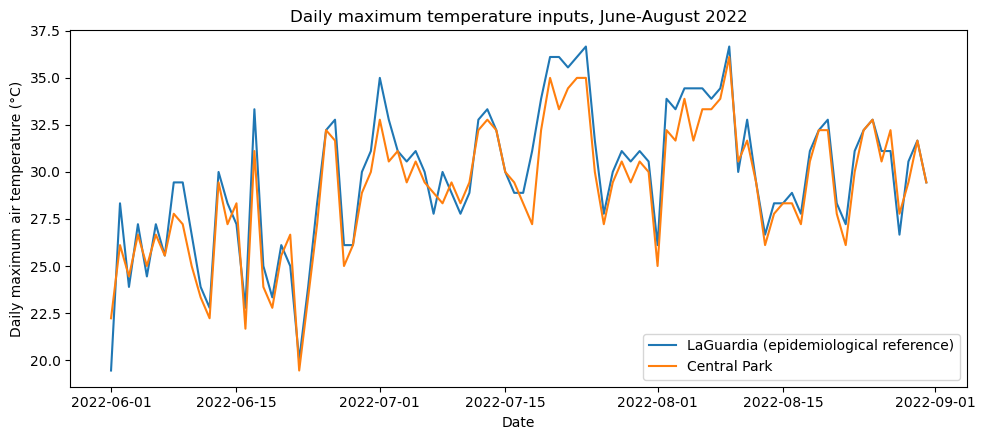

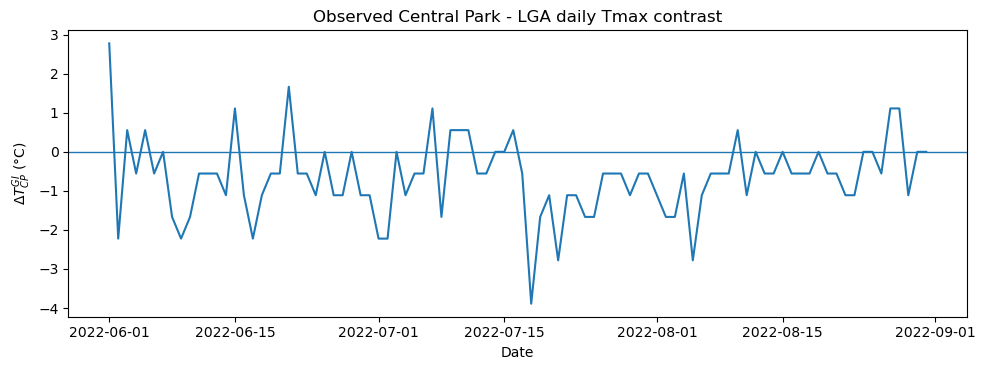

In [3]:
# Plot daily Tmax and Central Park-LGA contrast

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily["date"], daily["T_epi_C"], label="LaGuardia (epidemiological reference)")
ax.plot(daily["date"], daily["T_CP_C"], label="Central Park")
ax.set_ylabel("Daily maximum air temperature (°C)")
ax.set_xlabel("Date")
ax.set_title("Daily maximum temperature inputs, June-August 2022")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_tmax_centralpark_lga.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhline(0, linewidth=1)
ax.plot(daily["date"], daily["deltaT_CP_C"])
ax.set_ylabel(r"$\Delta T^{GI}_{CP}$ (°C)")
ax.set_xlabel("Date")
ax.set_title("Observed Central Park - LGA daily Tmax contrast")
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_station_contrast.png", dpi=200)
plt.show()

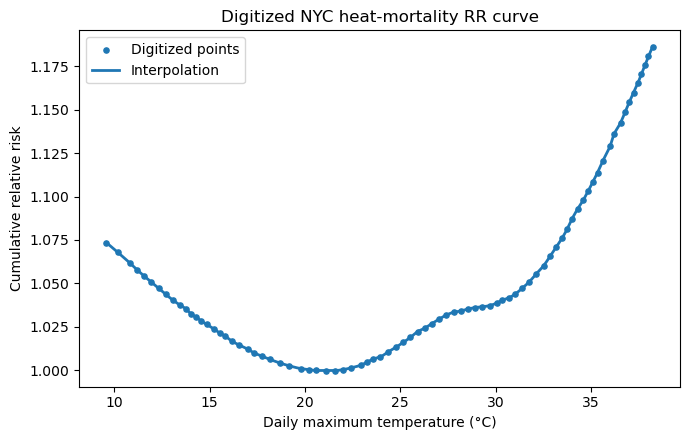

In [4]:
# Digitized NYC RR(Tmax) curve and interpolation

def load_rr_curve(path):
    # Read headerless so the first numeric point is never consumed as a header.
    raw = pd.read_csv(path, header=None, sep=None, engine="python", comment="#")
    raw = raw.apply(pd.to_numeric, errors="coerce").dropna(how="all")

    valid_cols = [c for c in raw.columns if raw[c].notna().sum() >= 4]
    if len(valid_cols) < 2:
        raise ValueError("RR CSV must contain at least two numeric columns (temperature, RR).")

    rr = raw[valid_cols[:2]].copy()
    rr.columns = ["T_raw", "RR"]
    rr = rr.dropna()

    # Detect input unit. The supplied WebPlotDigitizer export is in °F.
    if rr["T_raw"].median() > 60:
        rr["T_C"] = (rr["T_raw"] - 32.0) * 5.0 / 9.0
    else:
        rr["T_C"] = rr["T_raw"]

    # Average duplicated x values if present, then sort.
    rr = rr.groupby("T_C", as_index=False)["RR"].mean().sort_values("T_C")
    return rr

rr_curve = load_rr_curve(RR_PATH)
rr_x = rr_curve["T_C"].to_numpy(float)
rr_y = rr_curve["RR"].to_numpy(float)

if HAVE_SCIPY:
    _rr_interp = PchipInterpolator(rr_x, rr_y, extrapolate=False)
else:
    _rr_interp = None

def RR_of_T_C(T_C):
    """Evaluate digitized cumulative RR curve at absolute daily Tmax in °C."""
    arr = np.asarray(T_C, dtype=float)
    if np.nanmin(arr) < rr_x.min() or np.nanmax(arr) > rr_x.max():
        raise ValueError(
            f"RR query outside digitized curve domain "
            f"[{rr_x.min():.2f}, {rr_x.max():.2f}] °C."
        )
    if HAVE_SCIPY:
        out = np.asarray(_rr_interp(arr), dtype=float)
    else:
        out = np.interp(arr, rr_x, rr_y)
    return out.item() if np.ndim(T_C) == 0 else out

def dRR_dT_C(T_C, h=1e-3):
    """Numerical derivative of RR(T) in 1/°C, used only at zero ΔT."""
    T = np.asarray(T_C, dtype=float)
    return (RR_of_T_C(T + h) - RR_of_T_C(T - h)) / (2.0 * h)

# Diagnostic plot
xx = np.linspace(rr_x.min(), rr_x.max(), 500)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(rr_x, rr_y, s=14, label="Digitized points")
ax.plot(xx, RR_of_T_C(xx), linewidth=2, label="Interpolation")
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("Cumulative relative risk")
ax.set_title("Digitized NYC heat-mortality RR curve")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rr_temperature_curve.png", dpi=200)
plt.show()


## Mortality-based DALY weighting

The case study retains the manuscript's age-weighting approach because age-specific natural-cause deaths were not available. The age distribution of all-cause mortality is therefore used as a proxy for distributing attributable deaths across age groups. The calculation below reproduces the manuscript's mean remaining life expectancy of approximately **15.82 years per attributable death**.

This output is referred to as **mortality-based DALY** because YLD is outside the scope of the method.

In [5]:
# YLL weighting from the manuscript's 2022 NYC table

age_ranges = [
    "Under 5","5-9","10-14","15-19","20-24","25-29","30-34","35-39",
    "40-44","45-49","50-54","55-59","60-64","65-69","70-74","75-79",
    "80-84","≥85"
]

deaths_all_age = np.array([
    503, 63, 80, 154, 341, 597, 829, 1081, 1266, 1576, 2304, 3485,
    4670, 5487, 6196, 6728, 7249, 17987
], dtype=float)

mid_ages = np.array([2,7,12,17,22,27,32,37,42,47,52,57,62,67,72,77,82,90])

mean_LE = np.array([
    77.2,72.3,67.3,62.4,57.6,52.9,48.2,43.5,38.9,34.4,29.9,25.7,
    21.7,17.9,14.3,10.9,8.0,4.5
], dtype=float)

age_weights = deaths_all_age / deaths_all_age.sum()
yll_contribution = age_weights * mean_LE
YLL_BAR = float(yll_contribution.sum())

yll_table = pd.DataFrame({
    "age_range": age_ranges,
    "all_cause_deaths": deaths_all_age.astype(int),
    "death_share": age_weights,
    "mid_age": mid_ages,
    "remaining_LE_y": mean_LE,
    "weighted_YLL": yll_contribution,
})

print(yll_table)
print(f"\nMean YLL per attributable death = {YLL_BAR:.4f} years/death")
assert np.isclose(deaths_all_age.sum(), N_ALL_ANNUAL_2022)
yll_table.to_csv(OUTPUT_DIR / "yll_weighting_2022.csv", index=False)

   age_range  all_cause_deaths  death_share  mid_age  remaining_LE_y  \
0    Under 5               503     0.008301        2            77.2   
1        5-9                63     0.001040        7            72.3   
2      10-14                80     0.001320       12            67.3   
3      15-19               154     0.002541       17            62.4   
4      20-24               341     0.005627       22            57.6   
5      25-29               597     0.009852       27            52.9   
6      30-34               829     0.013681       32            48.2   
7      35-39              1081     0.017839       37            43.5   
8      40-44              1266     0.020892       42            38.9   
9      45-49              1576     0.026008       47            34.4   
10     50-54              2304     0.038022       52            29.9   
11     55-59              3485     0.057512       57            25.7   
12     60-64              4670     0.077068       62            

In [6]:
# Month-specific natural-cause mortality proxy for the 92-day study period

days_in_month = {6: 30, 7: 31, 8: 31}

monthly_mortality = pd.DataFrame({
    "month": [6, 7, 8],
    "all_cause_deaths": [MONTHLY_ALL_CAUSE_2022[m] for m in [6, 7, 8]],
    "days": [days_in_month[m] for m in [6, 7, 8]],
})
monthly_mortality["all_cause_deaths_per_day"] = (
    monthly_mortality["all_cause_deaths"] / monthly_mortality["days"]
)
monthly_mortality["natural_cause_deaths_per_day_proxy"] = (
    monthly_mortality["all_cause_deaths_per_day"] * NATURAL_TO_ALL_RATIO
)

daily["n_t_natural_deaths"] = daily["date"].dt.month.map(
    monthly_mortality.set_index("month")["natural_cause_deaths_per_day_proxy"]
)

if daily["n_t_natural_deaths"].isna().any():
    raise ValueError("Missing monthly mortality proxy for one or more study days.")

print(monthly_mortality)
monthly_mortality.to_csv(OUTPUT_DIR / "monthly_mortality_proxy_2022.csv", index=False)
daily.to_csv(OUTPUT_DIR / "daily_temperature_mortality_inputs.csv", index=False)

   month  all_cause_deaths  days  all_cause_deaths_per_day  \
0      6              4376    30                145.866667   
1      7              4709    31                151.903226   
2      8              4774    31                154.000000   

   natural_cause_deaths_per_day_proxy  
0                          131.721962  
1                          137.173155  
2                          139.066605  


## Spatial inputs

The spatial workflow uses:

1. **NYC Parks Properties** for the Central Park polygon.
2. **NYC DCP 2020 Census Blocks** for Manhattan block geometry and 15-digit Census block GEOIDs.
3. **2020 Decennial Census PL 94-171** variable `P1_001N` for block population.
4. **NYC DCP Borough Boundaries** for the NYC context map.
5. **Esri World Imagery** as the aerial basemap for map visualization. Native Web-Mercator map tiles are used when `contextily` is available; the Esri export service is retained as a fallback.
6. **NOAA/NCEI station coordinates** for Central Park (USW00094728) and LaGuardia Airport (USW00014732).

All analytical geometry is transformed to **EPSG:32618 (WGS 84 / UTM Zone 18N)** before constructing the fixed 100 m × 100 m receptor grid and performing area calculations. Map-only layers are transformed to Web Mercator (EPSG:3857) when displayed over the Esri basemap.

### Census API authentication

The U.S. Census Data API requires an API key for the population query used here. If no cached/local block-population file is available, the credential cell prompts for the key using `getpass()`. The input is hidden and the key is stored only in the current Python process as `CENSUS_API_KEY`; it is not written into the notebook or exported result files.

After the block-population table is downloaded successfully, it is cached locally at:

`lcr_spatial_cache/manhattan_2020_block_population.csv`

Subsequent runs can use that cache without prompting for the key. A local CSV containing `GEOID`/`GEOID20` and `P1_001N`/`pop_2020`/`population` columns may also be used.

In [7]:
# Spatial-data acquisition helpers

PARKS_API = "https://data.cityofnewyork.us/resource/enfh-gkve.geojson"
BLOCKS_API = "https://data.cityofnewyork.us/resource/wmsu-5muw.geojson"
CENSUS_PL_API = "https://api.census.gov/data/2020/dec/pl"
BOROUGHS_API = "https://data.cityofnewyork.us/resource/gthc-hcne.geojson"
ESRI_WORLD_IMAGERY_EXPORT = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/export"

PARK_CACHE = CACHE_DIR / "central_park_parks_properties.geojson"
BLOCK_CACHE = CACHE_DIR / "manhattan_2020_census_blocks.geojson"
POP_CACHE = CACHE_DIR / "manhattan_2020_block_population.csv"
BOROUGH_CACHE = CACHE_DIR / "nyc_borough_boundaries.geojson"

LOCAL_POP_CANDIDATES = [
    INPUT_DIR / "nyc_block_population_2020.csv",
    INPUT_DIR / "manhattan_block_population_2020.csv",
]

def _download_json(url, params=None, timeout=180):
    """Download JSON/GeoJSON with a user-agent and useful error context."""
    headers = {
        "User-Agent": (
            "GI-LCR-LCIA-research-notebook/1.1 "
            "(academic reproducibility; NYC Open Data and U.S. Census)"
        )
    }
    r = requests.get(url, params=params, headers=headers, timeout=timeout)
    try:
        r.raise_for_status()
    except requests.HTTPError as exc:
        raise RuntimeError(
            f"Download failed ({r.status_code}) for {r.url}\n"
            f"Response excerpt: {r.text[:500]}"
        ) from exc

    try:
        return r.json()
    except ValueError as exc:
        raise RuntimeError(
            "The server returned a response that could not be parsed as JSON.\n"
            f"URL: {r.url}\n"
            f"HTTP status: {r.status_code}\n"
            f"Content-Type: {r.headers.get('Content-Type')}\n"
            f"Response excerpt: {r.text[:500]}"
        ) from exc

def _union_geometry(gdf):
    """Compatibility helper for GeoPandas/Shapely versions."""
    if hasattr(gdf.geometry, "union_all"):
        return gdf.geometry.union_all()
    return gdf.geometry.unary_union

def load_central_park_polygon():
    """
    Load Central Park from the official NYC Parks Properties dataset.

    The API is queried using NAME311. If the filtered query ever fails because
    the dataset schema changes, the function falls back to downloading the full
    (small) Parks Properties table and searches text name fields locally.
    """
    if PARK_CACHE.exists():
        parks = gpd.read_file(PARK_CACHE)
    else:
        data = None
        try:
            data = _download_json(
                PARKS_API,
                {
                    "$limit": 5000,
                    "$where": "name311='Central Park'",
                },
            )
        except Exception as exc:
            warnings.warn(
                "Filtered NYC Parks query failed; downloading the full Parks "
                f"Properties table and filtering locally. Details: {exc}"
            )

        if not data or not data.get("features"):
            data = _download_json(PARKS_API, {"$limit": 5000})
            tmp = CACHE_DIR / "_parks_all.geojson"
            tmp.write_text(json.dumps(data), encoding="utf-8")
            parks_all = gpd.read_file(tmp)

            candidate_cols = [
                c for c in parks_all.columns
                if any(token in c.lower() for token in ["name", "sign"])
                and c != "geometry"
            ]
            mask = pd.Series(False, index=parks_all.index)
            for c in candidate_cols:
                mask |= (
                    parks_all[c]
                    .astype(str)
                    .str.contains(r"\bCentral Park\b", case=False, na=False, regex=True)
                )
            parks = parks_all.loc[mask].copy()
            if parks.empty:
                raise RuntimeError(
                    "Could not identify Central Park in the NYC Parks Properties dataset. "
                    f"Name-like columns inspected: {candidate_cols}"
                )
            parks.to_file(PARK_CACHE, driver="GeoJSON")
            tmp.unlink(missing_ok=True)
        else:
            PARK_CACHE.write_text(json.dumps(data), encoding="utf-8")
            parks = gpd.read_file(PARK_CACHE)

    if parks.empty:
        raise RuntimeError("NYC Parks data returned no Central Park features.")

    if parks.crs is None:
        parks = parks.set_crs("EPSG:4326")

    parks = parks.to_crs(SPATIAL_CRS)
    park_geom = _union_geometry(parks)

    park = gpd.GeoDataFrame(
        {"site": ["Central Park"]},
        geometry=[park_geom],
        crs=SPATIAL_CRS,
    )
    return park

def load_manhattan_block_geometry():
    """Load official NYC DCP 2020 Census block polygons for Manhattan."""
    if BLOCK_CACHE.exists():
        blocks = gpd.read_file(BLOCK_CACHE)
    else:
        # Manhattan is well below the requested 10,000-row limit.
        data = _download_json(
            BLOCKS_API,
            {
                "$limit": 10000,
                "$where": "boroname='Manhattan'",
            },
        )
        BLOCK_CACHE.write_text(json.dumps(data), encoding="utf-8")
        blocks = gpd.read_file(BLOCK_CACHE)

    if blocks.empty:
        raise RuntimeError("NYC Open Data query returned no Manhattan Census blocks.")

    if blocks.crs is None:
        blocks = blocks.set_crs("EPSG:4326")

    geoid_col = next((c for c in blocks.columns if c.lower() == "geoid"), None)
    if geoid_col is None:
        raise ValueError(
            f"Could not identify Census block GEOID column: {list(blocks.columns)}"
        )

    blocks["GEOID"] = (
        blocks[geoid_col]
        .astype(str)
        .str.replace(r"\D", "", regex=True)
        .str[-15:]
        .str.zfill(15)
    )

    blocks = blocks.to_crs(SPATIAL_CRS)

    # Repair any rare invalid features before polygon overlay.
    if hasattr(blocks.geometry, "make_valid"):
        blocks["geometry"] = blocks.geometry.make_valid()
    else:
        blocks["geometry"] = blocks.geometry.buffer(0)

    return blocks

def _normalize_local_population_csv(pop, source_name):
    """Normalize an optional local block-population export to GEOID + pop_2020."""
    geoid_col = next(
        (c for c in pop.columns if c.lower() in {"geoid", "geoid20"}),
        None,
    )
    pop_col = next(
        (c for c in pop.columns if c.lower() in {"pop_2020", "population", "p1_001n"}),
        None,
    )
    if geoid_col is None or pop_col is None:
        raise ValueError(
            f"{source_name}: expected GEOID/GEOID20 and "
            "pop_2020/population/P1_001N columns."
        )

    out = pd.DataFrame({
        "GEOID": (
            pop[geoid_col]
            .astype(str)
            .str.replace(r"\D", "", regex=True)
            .str[-15:]
            .str.zfill(15)
        ),
        "pop_2020": pd.to_numeric(pop[pop_col], errors="coerce"),
    }).dropna()

    return out.groupby("GEOID", as_index=False)["pop_2020"].sum()

def load_manhattan_block_population():
    """
    Load 2020 PL 94-171 total population (P1_001N) for Manhattan Census blocks.

    Priority
    --------
    1. Cached result from a previous successful run.
    2. User-supplied local CSV export.
    3. Official U.S. Census Data API using CENSUS_API_KEY.

    The Census API key is never written to disk by this function.
    """
    if POP_CACHE.exists():
        pop = pd.read_csv(POP_CACHE, dtype={"GEOID": str})
        pop["GEOID"] = (
            pop["GEOID"]
            .astype(str)
            .str.replace(r"\D", "", regex=True)
            .str[-15:]
            .str.zfill(15)
        )
        pop["pop_2020"] = pd.to_numeric(pop["pop_2020"], errors="coerce")
        return pop[["GEOID", "pop_2020"]].dropna()

    for p in LOCAL_POP_CANDIDATES:
        if p.exists():
            pop = pd.read_csv(p, dtype=str)
            out = _normalize_local_population_csv(pop, p.name)
            out.to_csv(POP_CACHE, index=False)
            print(f"Using local Census block-population file: {p.name}")
            return out

    api_key = os.getenv("CENSUS_API_KEY", "").strip()
    if not api_key:
        raise RuntimeError(
            "A U.S. Census API key is required because no cached/local block-"
            "population file was found. Run the secure Census-key cell immediately "
            "before the spatial loading cell, then rerun this cell."
        )

    # requests supports repeated "in" parameters when supplied as a list of tuples.
    params = [
        ("get", "NAME,P1_001N"),
        ("for", "block:*"),
        ("in", "state:36"),
        ("in", "county:061"),  # New York County / Manhattan
        ("in", "tract:*"),
        ("key", api_key),
    ]

    headers = {
        "User-Agent": (
            "GI-LCR-LCIA-research-notebook/1.1 "
            "(academic reproducibility; U.S. Census)"
        )
    }

    r = requests.get(
        CENSUS_PL_API,
        params=params,
        headers=headers,
        timeout=180,
    )

    try:
        r.raise_for_status()
    except requests.HTTPError as exc:
        raise RuntimeError(
            f"Census population request failed ({r.status_code}) for {r.url}\n"
            f"Content-Type: {r.headers.get('Content-Type')}\n"
            f"Response excerpt: {r.text[:500]}"
        ) from exc

    content_type = (r.headers.get("Content-Type") or "").lower()
    if "json" not in content_type:
        raise RuntimeError(
            "The Census API did not return JSON. This commonly indicates an "
            "authentication or API-service response rather than Census data.\n"
            f"HTTP status: {r.status_code}\n"
            f"Content-Type: {r.headers.get('Content-Type')}\n"
            f"Response excerpt: {r.text[:500]}"
        )

    try:
        data = r.json()
    except ValueError as exc:
        raise RuntimeError(
            "The Census API response could not be parsed as JSON.\n"
            f"HTTP status: {r.status_code}\n"
            f"Content-Type: {r.headers.get('Content-Type')}\n"
            f"Response excerpt: {r.text[:500]}"
        ) from exc

    if not isinstance(data, list) or len(data) < 2:
        raise RuntimeError(
            "Census API returned no Manhattan block-population rows.\n"
            f"Response excerpt: {str(data)[:500]}"
        )

    header = data[0]
    required = {"P1_001N", "state", "county", "tract", "block"}
    missing = required.difference(header)
    if missing:
        raise RuntimeError(
            "Census API response is missing expected fields: "
            + ", ".join(sorted(missing))
        )

    pop = pd.DataFrame(data[1:], columns=header)

    pop["GEOID"] = (
        pop["state"].astype(str).str.zfill(2)
        + pop["county"].astype(str).str.zfill(3)
        + pop["tract"].astype(str).str.zfill(6)
        + pop["block"].astype(str).str.zfill(4)
    )
    pop["pop_2020"] = pd.to_numeric(pop["P1_001N"], errors="coerce")

    out = (
        pop[["GEOID", "pop_2020"]]
        .dropna()
        .groupby("GEOID", as_index=False)["pop_2020"]
        .sum()
    )

    out.to_csv(POP_CACHE, index=False)
    print(
        f"Downloaded and cached {len(out):,} Manhattan block-population rows "
        f"at {POP_CACHE}"
    )
    return out

print("Spatial source functions defined. Downloads will be cached in:", CACHE_DIR)



def load_nyc_borough_boundaries():
    """Load NYC Department of City Planning borough boundaries for mapping."""
    if BOROUGH_CACHE.exists():
        boroughs = gpd.read_file(BOROUGH_CACHE)
    else:
        data = _download_json(BOROUGHS_API, {"$limit": 10})
        BOROUGH_CACHE.write_text(json.dumps(data), encoding="utf-8")
        boroughs = gpd.read_file(BOROUGH_CACHE)

    if boroughs.empty:
        raise RuntimeError("NYC Open Data returned no borough-boundary features.")
    if boroughs.crs is None:
        boroughs = boroughs.set_crs("EPSG:4326")
    return boroughs


def add_esri_world_imagery(ax, bounds_3857, cache_name, width_px=1600):
    """Add an Esri World Imagery raster behind Web-Mercator vector layers."""
    xmin, ymin, xmax, ymax = map(float, bounds_3857)
    span_x = max(xmax - xmin, 1.0)
    span_y = max(ymax - ymin, 1.0)
    height_px = max(500, int(round(width_px * span_y / span_x)))
    height_px = min(height_px, 2000)

    image_path = CACHE_DIR / cache_name
    if not image_path.exists():
        params = {
            "bbox": f"{xmin},{ymin},{xmax},{ymax}",
            "bboxSR": "3857",
            "imageSR": "3857",
            "size": f"{int(width_px)},{int(height_px)}",
            "format": "png32",
            "transparent": "false",
            "f": "image",
        }
        headers = {"User-Agent": "GI-LCR-LCIA-research-notebook/1.2"}
        r = requests.get(ESRI_WORLD_IMAGERY_EXPORT, params=params, headers=headers, timeout=180)
        if not r.ok or "image" not in (r.headers.get("Content-Type") or "").lower():
            warnings.warn(
                "Esri World Imagery could not be downloaded; the vector map will still be produced. "
                f"HTTP {r.status_code}; response excerpt: {r.text[:200]}"
            )
            return False
        image_path.write_bytes(r.content)

    img = Image.open(image_path)
    ax.imshow(img, extent=(xmin, xmax, ymin, ymax), origin="upper")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    return True


def add_esri_world_imagery_tiles(ax, zoom=None, alpha=1.0):
    """Add Esri World Imagery without reprojecting the raster when the axes are EPSG:3857.

    Contextily is preferred because it retrieves native Web-Mercator tiles at the
    requested zoom. Keeping both vectors and imagery in EPSG:3857 avoids an
    additional raster reprojection step and helps preserve crisp shoreline detail.
    """
    if not HAVE_CONTEXTILY:
        return False

    kwargs = {
        "source": cx.providers.Esri.WorldImagery,
        "attribution_size": 5,
        "interpolation": "none",
        "alpha": alpha,
    }
    if zoom is not None:
        kwargs["zoom"] = int(zoom)
    cx.add_basemap(ax, **kwargs)
    return True


def plot_outside_geometry_mask(ax, focus_gdf, facecolor=(0.18, 0.18, 0.18, 0.78)):
    """Darken the map outside a polygonal focus area while leaving the focus visible."""
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    extent_geom = box(xmin, ymin, xmax, ymax)
    focus_geom = _union_geometry(focus_gdf).buffer(0).intersection(extent_geom).buffer(0)
    mask_geom = extent_geom.difference(focus_geom)
    if not mask_geom.is_empty:
        gpd.GeoDataFrame(geometry=[mask_geom], crs=focus_gdf.crs).plot(
            ax=ax,
            facecolor=facecolor,
            edgecolor="none",
            zorder=2,
        )


Spatial source functions defined. Downloads will be cached in: /Users/alanasmith/Documents/Jupyter_Notebooks/UHI LCR Method/NYC Case Study/lcr_spatial_cache


In [8]:
# Census API credential setup. The key is requested only when a cached/local
# population table is unavailable and is retained only in the current process.

from getpass import getpass

_have_population_file = (
    POP_CACHE.exists()
    or any(p.exists() for p in LOCAL_POP_CANDIDATES)
)

if _have_population_file:
    print("Census population cache/local file found; API key prompt skipped.")
elif os.getenv("CENSUS_API_KEY", "").strip():
    print("CENSUS_API_KEY is already set in the current Python environment.")
else:
    _census_key = getpass(
        "Enter your U.S. Census API key (input hidden; press Enter when done): "
    ).strip()

    if not _census_key:
        raise RuntimeError(
            "No Census API key was entered. Obtain a free key from "
            "https://api.census.gov/data/key_signup.html and rerun this cell."
        )

    os.environ["CENSUS_API_KEY"] = _census_key
    del _census_key
    print(
        "Census API key loaded for this Python session only. "
        "It has not been written to the notebook or disk."
    )


Census population cache/local file found; API key prompt skipped.


In [9]:
# Load and validate Central Park and Census block spatial data
#
# Internet access is required on the first run unless cache/local files exist.

print("1. Loading Central Park polygon...")
park = load_central_park_polygon()
print("   ✓ Central Park loaded")

print("2. Loading Manhattan Census block geometry...")
blocks = load_manhattan_block_geometry()
print(f"   ✓ Block geometry loaded ({len(blocks):,} polygons)")

print("3. Loading Manhattan Census block population...")
block_pop = load_manhattan_block_population()
print(f"   ✓ Block population loaded ({len(block_pop):,} GEOIDs)")

print("4. Joining block geometry to block population...")
blocks = blocks.merge(
    block_pop,
    on="GEOID",
    how="left",
    validate="one_to_one",
    indicator=True,
)

match_share = (blocks["_merge"] == "both").mean()
unmatched_n = int((blocks["_merge"] != "both").sum())

if match_share < 0.99:
    warnings.warn(
        f"Only {match_share:.1%} of Manhattan block geometries matched Census population "
        f"({unmatched_n:,} unmatched geometries). Inspect GEOID formatting before "
        "interpreting results."
    )

blocks = blocks.drop(columns="_merge")
blocks["pop_2020"] = blocks["pop_2020"].fillna(0.0)

# Express 2020 block counts on a 2022 population basis using the uniform
# citywide NYC 2022/2020 population ratio.
blocks["pop_2022"] = blocks["pop_2020"] * POP_SCALE_2020_TO_2022
print("   ✓ Geometry-population join complete")

A_GI_M2 = float(park.geometry.area.iloc[0])
park_area_km2 = A_GI_M2 / 1e6

if not (3.0 <= park_area_km2 <= 3.8):
    warnings.warn(
        f"Central Park polygon area is {park_area_km2:.3f} km², outside the "
        "expected approximate range. Inspect the Parks Properties feature selection."
    )

manhattan_pop_loaded = float(blocks["pop_2020"].sum())
if not np.isclose(manhattan_pop_loaded, P_MANHATTAN_2020, rtol=0.01):
    warnings.warn(
        f"Loaded Manhattan 2020 block population ({manhattan_pop_loaded:,.0f}) "
        f"differs from the expected Census total ({P_MANHATTAN_2020:,.0f}) by >1%."
    )

print()
print("Spatial input validation summary")
print("--------------------------------")
print(f"Central Park polygon area: {A_GI_M2:,.0f} m² ({park_area_km2:.3f} km²)")
print(f"Manhattan Census blocks loaded: {len(blocks):,}")
print(f"2020 Manhattan block population loaded: {manhattan_pop_loaded:,.0f}")
print(f"Geometry-population GEOID match rate: {match_share:.2%}")
print(f"Uniform 2020→2022 population scale factor: {POP_SCALE_2020_TO_2022:.6f}")


1. Loading Central Park polygon...
   ✓ Central Park loaded
2. Loading Manhattan Census block geometry...
   ✓ Block geometry loaded (3,929 polygons)
3. Loading Manhattan Census block population...
   ✓ Block population loaded (4,043 GEOIDs)
4. Joining block geometry to block population...
   ✓ Geometry-population join complete

Spatial input validation summary
--------------------------------
Central Park polygon area: 3,395,211 m² (3.395 km²)
Manhattan Census blocks loaded: 3,929
2020 Manhattan block population loaded: 1,694,214
Geometry-population GEOID match rate: 100.00%
Uniform 2020→2022 population scale factor: 0.946810


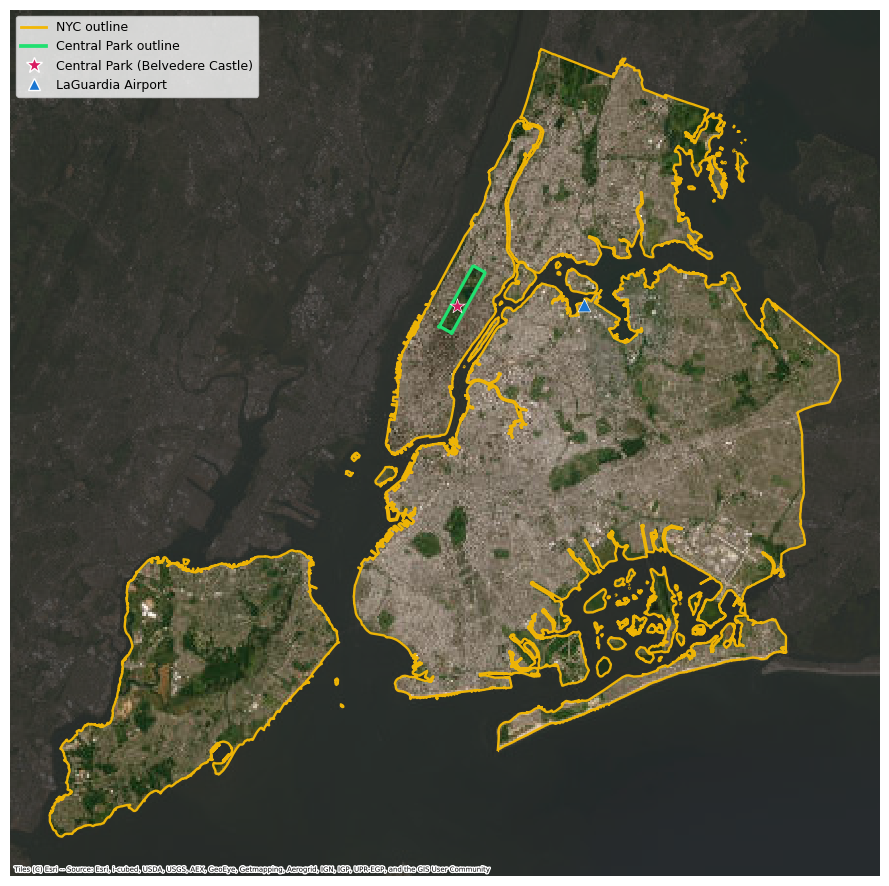

In [10]:
# Figure 2: NYC case-study context map

boroughs = load_nyc_borough_boundaries()
nyc_outline = gpd.GeoDataFrame(
    {"site": ["New York City"]},
    geometry=[_union_geometry(boroughs)],
    crs=boroughs.crs,
)

station_locations = gpd.GeoDataFrame(
    {
        "station": [
            "Central Park (Belvedere Castle)",
            "LaGuardia Airport",
        ]
    },
    geometry=[
        Point(-73.96925, 40.77898),
        Point(-73.88027, 40.77945),
    ],
    crs="EPSG:4326",
)

nyc_3857 = nyc_outline.to_crs("EPSG:3857")
park_3857 = park.to_crs("EPSG:3857")
stations_3857 = station_locations.to_crs("EPSG:3857")

xmin, ymin, xmax, ymax = nyc_3857.total_bounds
dx = xmax - xmin
dy = ymax - ymin
pad = 0.05
context_bounds = (
    xmin - dx * pad,
    ymin - dy * pad,
    xmax + dx * pad,
    ymax + dy * pad,
)

fig, ax = plt.subplots(figsize=(9, 9))
ax.set_xlim(context_bounds[0], context_bounds[2])
ax.set_ylim(context_bounds[1], context_bounds[3])

# Use native Web-Mercator tiles when contextily is available. This avoids a
# second raster reprojection step and preserves sharper coastlines and water edges.
basemap_added = add_esri_world_imagery_tiles(ax, zoom=10, alpha=1.0)
if not basemap_added:
    add_esri_world_imagery(
        ax,
        context_bounds,
        "esri_world_imagery_nyc_context.png",
        width_px=2400,
    )

# Subdue imagery outside the NYC administrative outline so the case-study area
# remains visually dominant without adding text labels over the aerial image.
plot_outside_geometry_mask(ax, nyc_3857)

NYC_COLOR = "#f2b705"
PARK_COLOR = "#20e070"
CP_COLOR = "#d81b60"
LGA_COLOR = "#1976d2"

nyc_3857.boundary.plot(
    ax=ax, color=NYC_COLOR, linewidth=1.7, alpha=0.98, zorder=4
)
park_3857.boundary.plot(
    ax=ax, color=PARK_COLOR, linewidth=2.3, zorder=5
)

cp_station = stations_3857.iloc[[0]]
lga_station = stations_3857.iloc[[1]]
cp_station.plot(
    ax=ax, marker="*", color=CP_COLOR, edgecolor="white", linewidth=0.5,
    markersize=125, zorder=6
)
lga_station.plot(
    ax=ax, marker="^", color=LGA_COLOR, edgecolor="white", linewidth=0.5,
    markersize=85, zorder=6
)

legend_handles = [
    Line2D([0], [0], color=NYC_COLOR, lw=2, label="NYC outline"),
    Line2D([0], [0], color=PARK_COLOR, lw=2.7, label="Central Park outline"),
    Line2D(
        [0], [0], marker="*", color="none", markerfacecolor=CP_COLOR,
        markeredgecolor="white", markersize=12, linestyle="None",
        label="Central Park (Belvedere Castle)"
    ),
    Line2D(
        [0], [0], marker="^", color="none", markerfacecolor=LGA_COLOR,
        markeredgecolor="white", markersize=9, linestyle="None",
        label="LaGuardia Airport"
    ),
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True, fontsize=9)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "figure2_nyc_case_study_aerial.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    FIG_DIR / "figure2_nyc_case_study_aerial.pdf",
    bbox_inches="tight",
    facecolor="white",
)
plt.show()


In [11]:
# Build fixed 100 m x 100 m receptor grid aligned to UTM coordinates

def make_aligned_grid(reference_geom, buffer_m, cell_size_m):
    region = reference_geom.buffer(buffer_m)
    minx, miny, maxx, maxy = region.bounds

    xmin = math.floor(minx / cell_size_m) * cell_size_m
    ymin = math.floor(miny / cell_size_m) * cell_size_m
    xmax = math.ceil(maxx / cell_size_m) * cell_size_m
    ymax = math.ceil(maxy / cell_size_m) * cell_size_m

    xs = np.arange(xmin, xmax, cell_size_m)
    ys = np.arange(ymin, ymax, cell_size_m)

    records = []
    cell_id = 0
    for x in xs:
        for y in ys:
            geom = box(x, y, x + cell_size_m, y + cell_size_m)
            if geom.intersects(region):
                records.append((cell_id, geom))
                cell_id += 1

    return gpd.GeoDataFrame(
        {"cell_id": [r[0] for r in records]},
        geometry=[r[1] for r in records],
        crs=SPATIAL_CRS,
    )

park_geom = park.geometry.iloc[0]
grid = make_aligned_grid(park_geom, MAX_REACH_M, GRID_SIZE_M)
grid["a_i_m2"] = GRID_CELL_AREA_M2
grid["centroid_distance_to_park_m"] = grid.geometry.centroid.distance(park_geom)

print(f"Receptor grid cells: {len(grid):,}")
print(f"Nominal cell area: {GRID_CELL_AREA_M2:,.0f} m²")

Receptor grid cells: 2,468
Nominal cell area: 10,000 m²


In [12]:
# Allocate Census block population to fixed receptor cells by polygon overlap

analysis_geom = _union_geometry(grid)
blocks_local = blocks[blocks.geometry.intersects(analysis_geom)].copy()
blocks_local["block_area_m2"] = blocks_local.geometry.area

intersections = gpd.overlay(
    grid[["cell_id", "geometry"]],
    blocks_local[["GEOID", "pop_2020", "pop_2022", "block_area_m2", "geometry"]],
    how="intersection",
    keep_geom_type=False,
)

intersections["intersection_area_m2"] = intersections.geometry.area
intersections["population_fraction"] = np.where(
    intersections["block_area_m2"] > 0,
    intersections["intersection_area_m2"] / intersections["block_area_m2"],
    0.0,
)
intersections["pop_2020_alloc"] = (
    intersections["pop_2020"] * intersections["population_fraction"]
)
intersections["pop_2022_alloc"] = (
    intersections["pop_2022"] * intersections["population_fraction"]
)

cell_population = (
    intersections.groupby("cell_id", as_index=False)[["pop_2020_alloc", "pop_2022_alloc"]]
    .sum()
)

grid = grid.merge(cell_population, on="cell_id", how="left")
grid[["pop_2020_alloc", "pop_2022_alloc"]] = (
    grid[["pop_2020_alloc", "pop_2022_alloc"]].fillna(0.0)
)
grid = grid.rename(columns={
    "pop_2020_alloc": "P_i_2020",
    "pop_2022_alloc": "P_i_2022",
})

print(f"2020 population allocated within max analysis domain: {grid.P_i_2020.sum():,.0f}")
print(f"2022-scaled population within max analysis domain: {grid.P_i_2022.sum():,.0f}")

grid.drop(columns="geometry").to_csv(
    OUTPUT_DIR / "receptor_grid_population_attributes.csv", index=False
)

2020 population allocated within max analysis domain: 747,382
2022-scaled population within max analysis domain: 707,628


## Literature-informed spatial temperature-influence fields

The Central Park station and LGA station provide a daily temperature contrast but do not resolve a two-dimensional temperature-response field around the park. The spatial calculations therefore use literature-informed operational influence reaches as sensitivity scenarios rather than empirical Central Park cooling distances.

Two spatial shapes are evaluated at each reach: a linear field and a normalized truncated-exponential field. Using the same reach for both shapes isolates sensitivity to the spatial decay form.

### Linear field

For scenario reach $D_s$, the linear multiplier is

$$
w_{\mathrm{lin},s}(d)=
\max\left(0,1-\frac{d}{D_s}\right),
$$

where $d=0$ for locations inside the park and otherwise denotes distance outward from the park polygon.

### Nonlinear exponential field

A conventional exponential $e^{-kd}$ approaches zero asymptotically. For a direct comparison using the same operational reach $D_s$, the nonlinear field is represented as a normalized, truncated exponential:

$$
w_{\mathrm{exp},s}(d)=
\begin{cases}
\dfrac{\exp(-\alpha d/D_s)-\exp(-\alpha)}
{1-\exp(-\alpha)}, & 0\le d\le D_s,\\[8pt]
0, & d>D_s.
\end{cases}
$$

The sensitivity analysis uses $\alpha=3$. This gives $w(0)=1$ and $w(D_s)=0$, so the park-edge amplitude and operational influence reach are identical to the corresponding linear field. The parameter $\alpha$ controls curvature and is not fitted to Central Park observations. As $\alpha\rightarrow0$, the normalized exponential approaches the linear form.

For either field type, the daily GI-attributable temperature field is

$$
\Delta T^{GI}_{i,t,s}
=
\Delta T^{GI}_{CP,t}\,\overline{w}_{i,s},
$$

where $\overline{w}_{i,s}$ is the area-average spatial multiplier within receptor cell $i$. The area average is evaluated numerically with a regular 5 × 5 set of equal-area sample points within each 100 m × 100 m receptor cell. This implements the spatial averaging equation

$$
\overline{\Delta T}^{GI}_{i,t,s}
=
\frac{1}{a_i}\int_{A_i}\Delta T^{GI}(x,y,t,s)\,dA.
$$

The three operational influence reaches are:

* **300 m:** a localized park-cooling sensitivity case informed by empirical urban-park studies (e.g., Chang & Li, 2014; Khalili et al., 2026).
* **500 m:** an intermediate case consistent with the approximately 498 m cooling range modeled by Toparlar et al. (2018).
* **1,400 m:** a long-reach case informed by the approximately 1.4 km directional influence reported for a large urban park by Yan et al. (2018).

These reach values parameterize the case-study sensitivity analysis. Site-specific measured or modeled spatial fields can replace these illustrative functions without changing the LCIA calculation structure.

In [13]:
# Numerical implementation of Methods Eq. (13): area-average spatial influence multipliers for each receptor cell

def _scenario_stub(decay_model, reach_m):
    """Column/file-safe identifier for a spatial field scenario."""
    return f"{decay_model}_{int(round(reach_m))}m"


def spatial_weight_from_distance(distance_m, reach_m, decay_model="linear", alpha=3.0):
    """
    Return the spatial temperature-influence multiplier at one or more distances.

    linear:
        w = max(0, 1 - d/D)

    exponential:
        normalized truncated exponential over the same operational reach D:
        w = [exp(-alpha*d/D) - exp(-alpha)] / [1 - exp(-alpha)]
        for 0 <= d <= D, and w = 0 beyond D.

    The exponential form is a nonlinear functional-form sensitivity. alpha is not
    fitted to Central Park and is therefore not a transferable empirical parameter.
    """
    d = np.asarray(distance_m, dtype=float)
    D = float(reach_m)
    if D <= 0:
        raise ValueError("reach_m must be > 0")

    if decay_model == "linear":
        w = np.maximum(0.0, 1.0 - d / D)

    elif decay_model == "exponential":
        a = float(alpha)
        if a <= 0:
            raise ValueError("alpha must be > 0 for the exponential sensitivity field")
        denom = 1.0 - np.exp(-a)
        w_inside = (np.exp(-a * d / D) - np.exp(-a)) / denom
        w = np.where(d <= D, np.maximum(0.0, w_inside), 0.0)

    else:
        raise ValueError(f"Unknown decay_model: {decay_model!r}")

    return np.clip(w, 0.0, 1.0)


def cell_weight_and_fraction(
    cell_geom,
    park_geom,
    reach_m,
    decay_model="linear",
    alpha=3.0,
    samples_per_axis=5,
):
    """
    Approximate Methods Eq. (13) and the influence-domain fraction over a receptor cell using equal-area sample points:

      mean_weight:
          area-average spatial multiplier used to calculate cell-average Delta T.

      within_fraction:
          fraction of sampled cell area lying inside the operational influence
          domain (park or <= reach from park boundary), used only for reporting
          influence area/population.

    Distance to the park polygon is zero for sample points inside the park.
    The influence-domain fraction depends on D but not on linear/exponential shape.
    """
    minx, miny, maxx, maxy = cell_geom.bounds
    n = int(samples_per_axis)

    dx = (maxx - minx) / n
    dy = (maxy - miny) / n
    xs = minx + (np.arange(n) + 0.5) * dx
    ys = miny + (np.arange(n) + 0.5) * dy

    distances = []
    for x in xs:
        for y in ys:
            distances.append(Point(float(x), float(y)).distance(park_geom))

    distances = np.asarray(distances, dtype=float)
    weights = spatial_weight_from_distance(
        distances,
        reach_m=reach_m,
        decay_model=decay_model,
        alpha=alpha,
    )

    mean_weight = float(weights.mean())
    within_fraction = float((distances <= reach_m).mean())
    return mean_weight, within_fraction

# Compute one weight column for each decay-shape/reach combination.
weight_cols = []
fraction_cols = []

for cfg in SPATIAL_FIELD_SCENARIOS:
    stub = _scenario_stub(cfg["decay_model"], cfg["reach_m"])
    wcol = f"w_{stub}"
    # phi is identical for linear and exponential scenarios with the same reach,
    # but retaining scenario-specific columns keeps downstream code explicit.
    pcol = f"phi_{stub}"

    alpha = (
        cfg["shape_alpha"]
        if np.isfinite(cfg["shape_alpha"])
        else EXPONENTIAL_SHAPE_ALPHA
    )

    values = [
        cell_weight_and_fraction(
            geom,
            park_geom,
            cfg["reach_m"],
            decay_model=cfg["decay_model"],
            alpha=alpha,
            samples_per_axis=CELL_AVERAGE_SAMPLES_PER_AXIS,
        )
        for geom in grid.geometry
    ]
    grid[wcol] = [v[0] for v in values]
    grid[pcol] = [v[1] for v in values]
    weight_cols.append(wcol)
    fraction_cols.append(pcol)

print(grid[["cell_id"] + weight_cols].describe())

print("\nApproximate influence-domain area and 2022-scaled resident population:")
for reach_label, reach_m in COOLING_REACH_SCENARIOS_M.items():
    # Domain is identical for both decay models at a given D; use the linear phi column.
    pcol = f"phi_{_scenario_stub('linear', reach_m)}"
    influence_area_m2 = float((grid[pcol] * grid["a_i_m2"]).sum())
    influence_population = float((grid[pcol] * grid["P_i_2022"]).sum())
    print(
        f"{reach_label}: approximate influence area = {influence_area_m2 / 1e6:.2f} km²; "
        f"2022-scaled residents within influence domain ≈ {influence_population:,.0f}."
    )


           cell_id  w_linear_300m  w_exponential_300m  w_linear_500m  \
count  2468.000000    2468.000000         2468.000000    2468.000000   
mean   1233.500000       0.202005            0.173241       0.249049   
std     712.594555       0.371618            0.353692       0.384072   
min       0.000000       0.000000            0.000000       0.000000   
25%     616.750000       0.000000            0.000000       0.000000   
50%    1233.500000       0.000000            0.000000       0.000000   
75%    1850.250000       0.144529            0.031540       0.485659   
max    2467.000000       1.000000            1.000000       1.000000   

       w_exponential_500m  w_linear_1400m  w_exponential_1400m  
count         2468.000000     2468.000000          2468.000000  
mean             0.198624        0.502603             0.329733  
std              0.359621        0.338062             0.353830  
min              0.000000        0.000000             0.000000  
25%              0.000000 

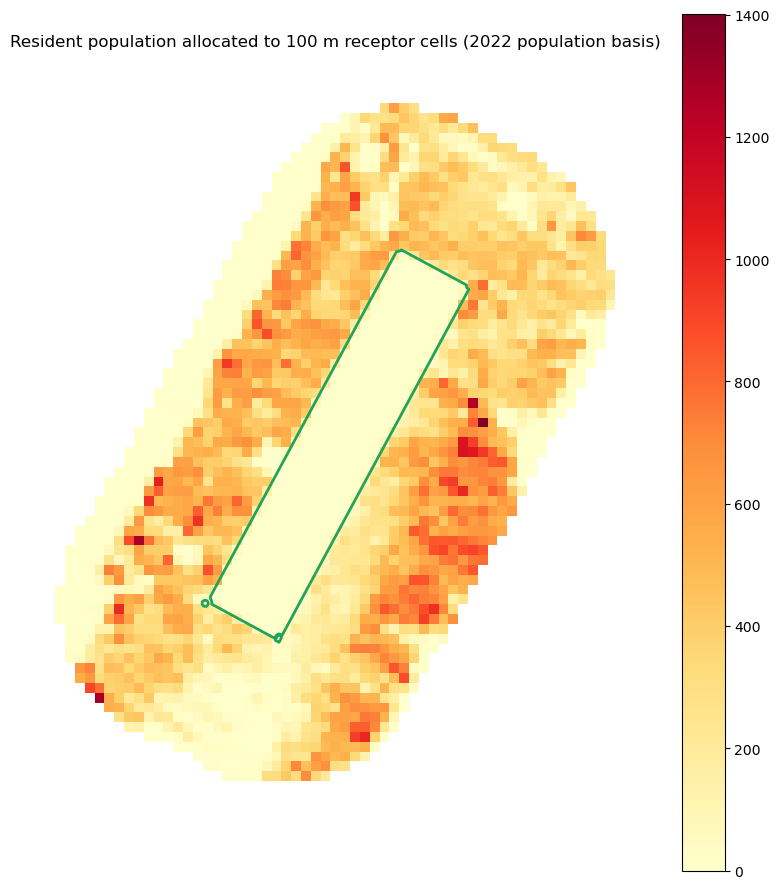

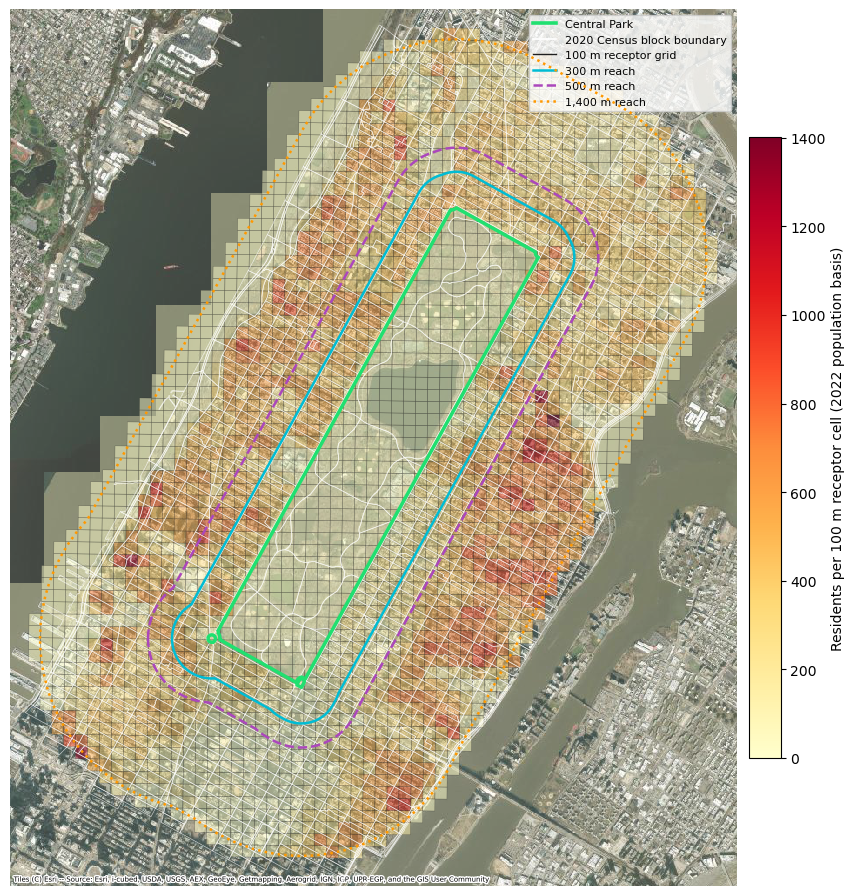

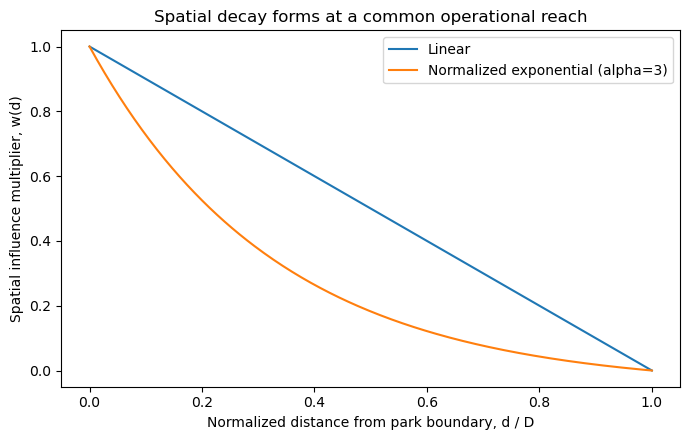

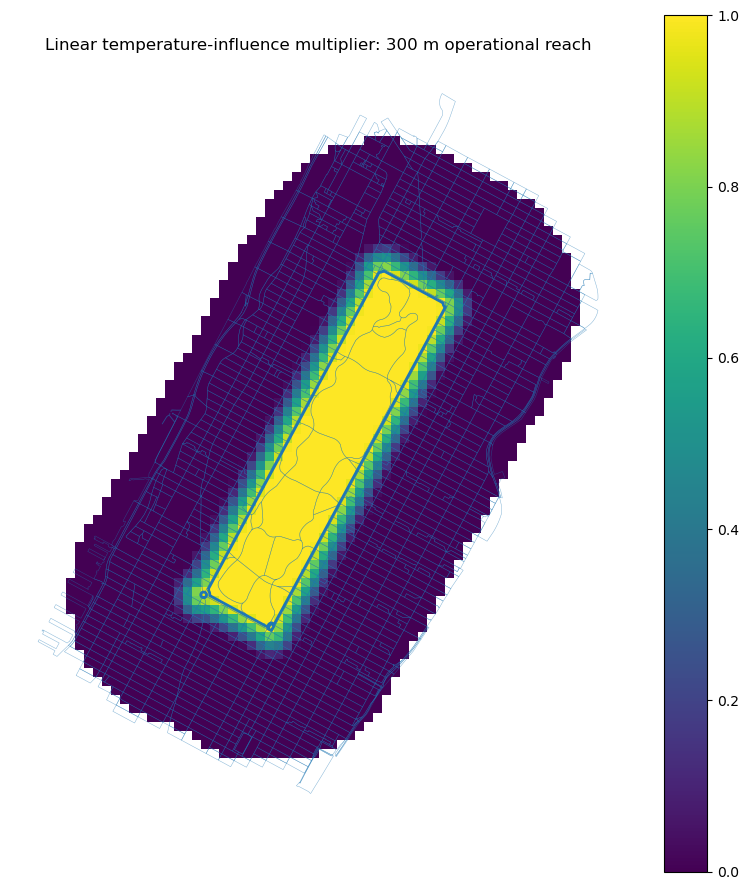

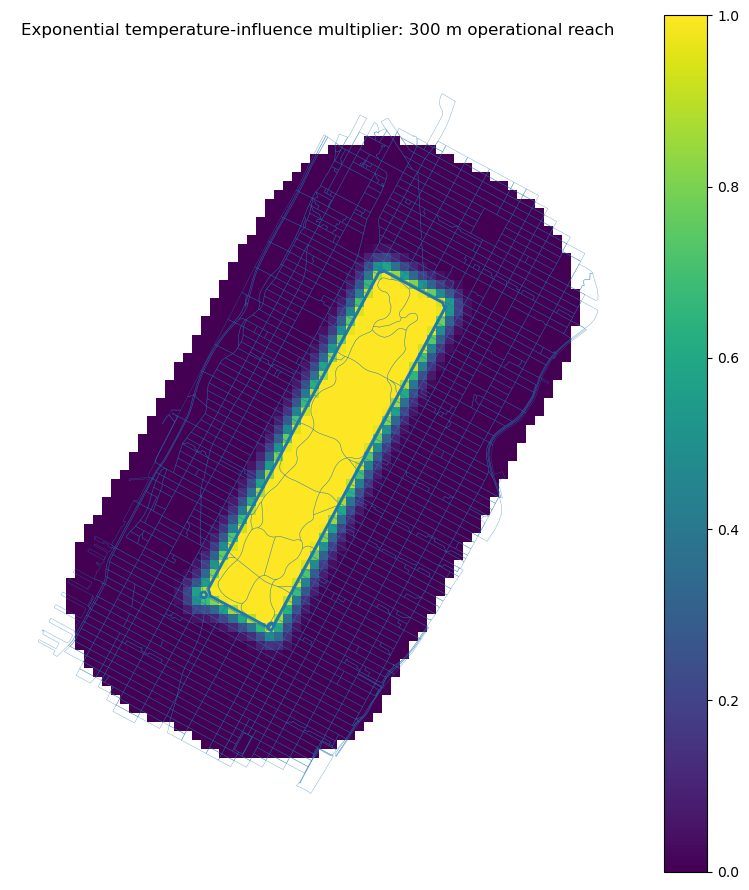

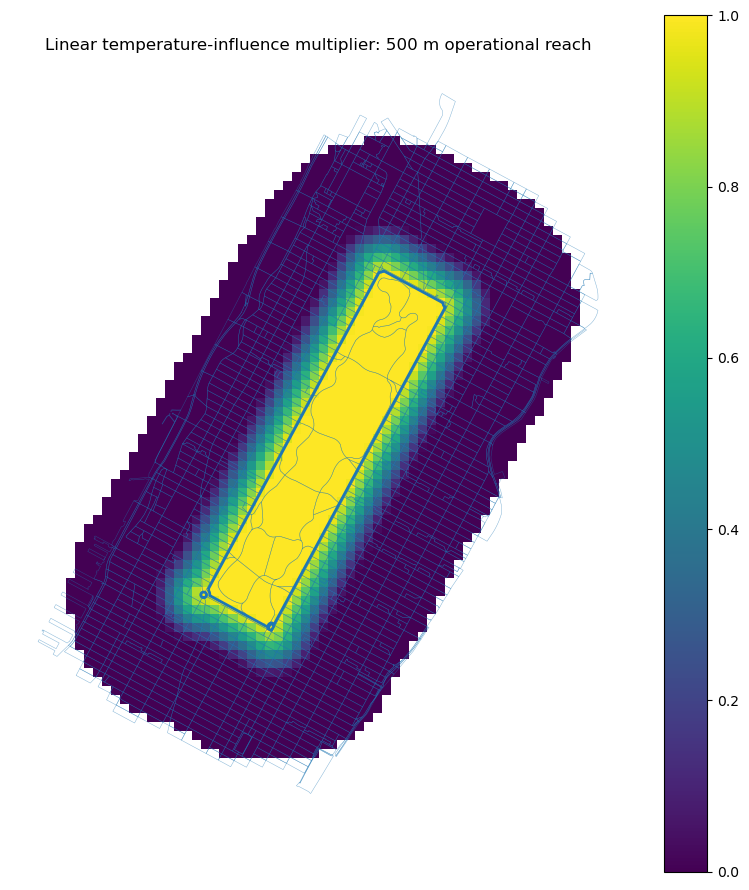

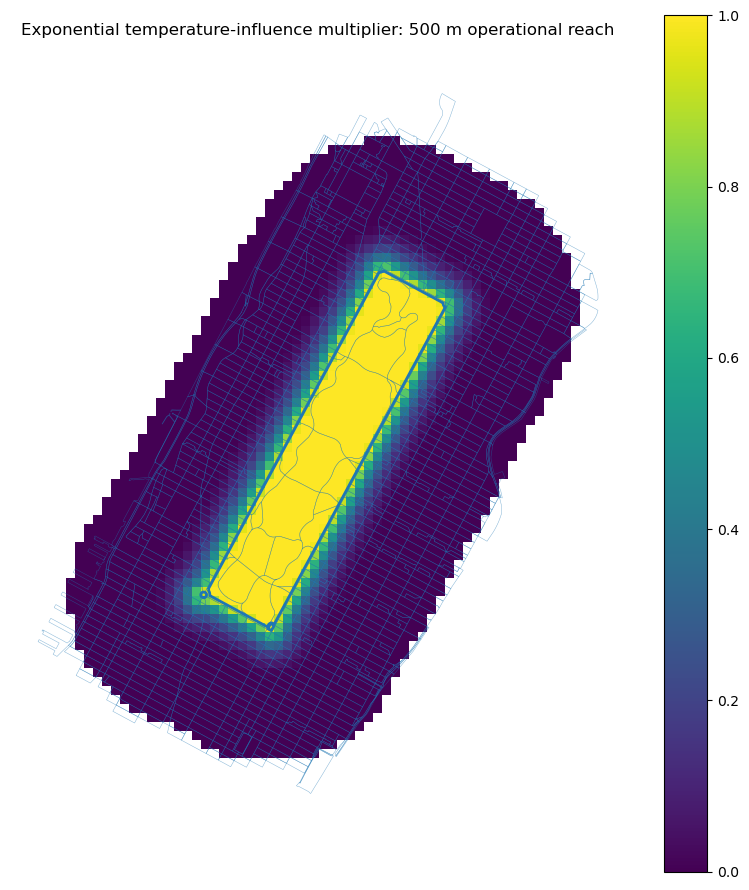

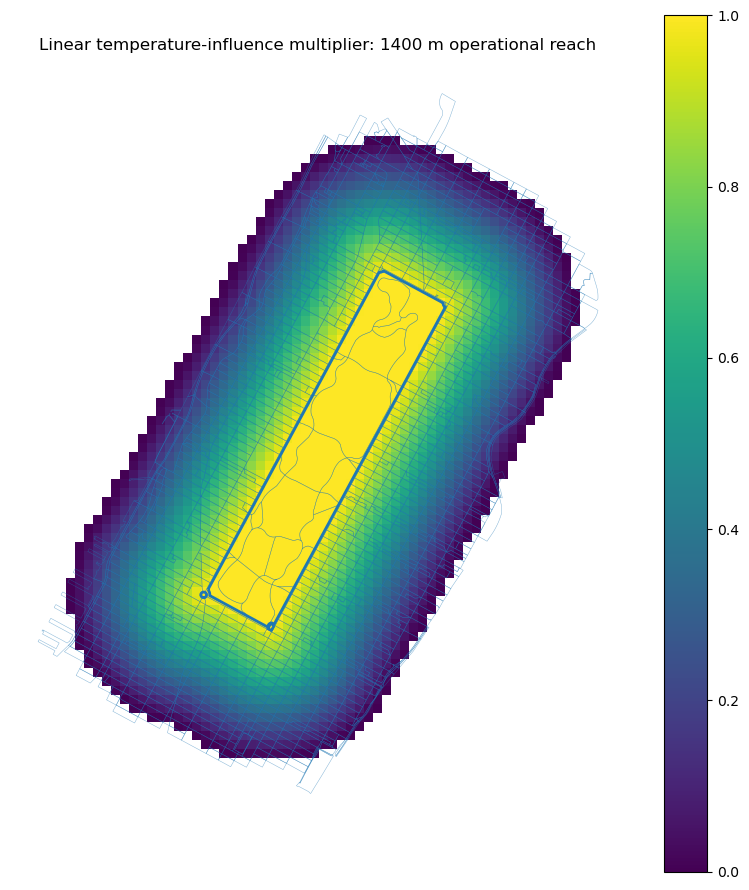

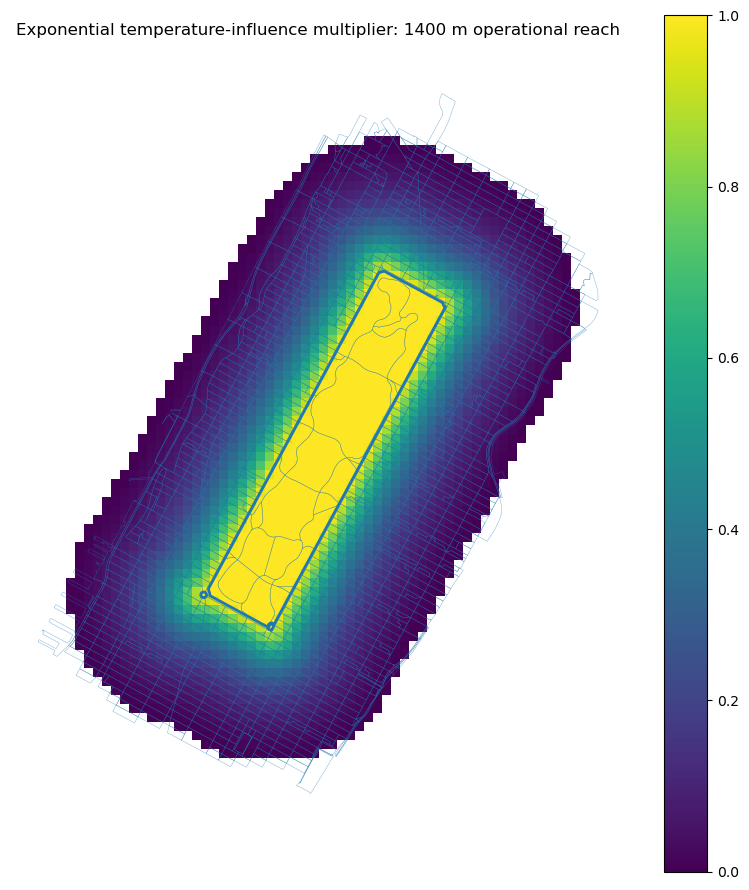

In [14]:
# Spatial visualizations

# Population allocated to the fixed receptor grid.
fig, ax = plt.subplots(figsize=(8, 9))
grid.plot(column="P_i_2022", ax=ax, legend=True, linewidth=0, cmap="YlOrRd")
park.boundary.plot(ax=ax, linewidth=2.0, color="#20a45b")
ax.set_title("Resident population allocated to 100 m receptor cells (2022 population basis)")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG_DIR / "receptor_grid_population.png", dpi=300, bbox_inches="tight")
plt.show()

# Combined local map: aerial imagery, Census blocks, receptor grid, population,
# Central Park, and the three literature-informed operational influence reaches.
grid_3857 = grid.to_crs("EPSG:3857")
blocks_local_3857 = blocks_local.to_crs("EPSG:3857")
park_3857 = park.to_crs("EPSG:3857")

local_domain_utm = park.geometry.iloc[0].buffer(MAX_REACH_M + 250.0)
local_domain_3857 = gpd.GeoSeries(
    [local_domain_utm], crs=SPATIAL_CRS
).to_crs("EPSG:3857").iloc[0]
xmin, ymin, xmax, ymax = local_domain_3857.bounds
local_bounds = (xmin, ymin, xmax, ymax)

fig, ax = plt.subplots(figsize=(9, 10))
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# A higher tile zoom is used for the local map so shorelines and street-scale
# features remain crisp. The imagery is lightly softened with transparency so
# analytical overlays remain legible.
basemap_added = add_esri_world_imagery_tiles(ax, zoom=14, alpha=0.76)
if not basemap_added:
    add_esri_world_imagery(
        ax,
        local_bounds,
        "esri_world_imagery_central_park_local.png",
        width_px=2600,
    )

# Population is shown as a semi-transparent receptor-cell fill. The 100 m grid
# and Census blocks use different line colors so both spatial structures can be
# inspected in the same map.
grid_3857.plot(
    column="P_i_2022",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    linewidth=0.30,
    edgecolor=(0.12, 0.12, 0.12, 0.52),
    alpha=0.50,
    legend_kwds={
        "label": "Residents per 100 m receptor cell (2022 population basis)",
        "shrink": 0.64,
        "pad": 0.015,
    },
    zorder=3,
)
blocks_local_3857.boundary.plot(
    ax=ax,
    color=(1.0, 1.0, 1.0, 0.70),
    linewidth=0.48,
    zorder=4,
)
park_3857.boundary.plot(
    ax=ax,
    color="#20e070",
    linewidth=2.5,
    zorder=7,
)

reach_styles = [
    ("300 m", 300.0, "#00bcd4", "-"),
    ("500 m", 500.0, "#ab47bc", "--"),
    ("1400 m", 1400.0, "#ff9800", ":"),
]
for reach_label, reach_m, color, linestyle in reach_styles:
    reach_geom = gpd.GeoSeries(
        [park.geometry.iloc[0].buffer(reach_m)], crs=SPATIAL_CRS
    ).to_crs("EPSG:3857")
    reach_geom.boundary.plot(
        ax=ax,
        color=color,
        linewidth=1.8,
        linestyle=linestyle,
        zorder=6,
    )

map_handles = [
    Line2D([0], [0], color="#20e070", lw=2.6, label="Central Park"),
    Line2D([0], [0], color="white", lw=1.2, label="2020 Census block boundary"),
    Line2D([0], [0], color=(0.12, 0.12, 0.12), lw=1.0, label="100 m receptor grid"),
    Line2D([0], [0], color="#00bcd4", lw=1.8, linestyle="-", label="300 m reach"),
    Line2D([0], [0], color="#ab47bc", lw=1.8, linestyle="--", label="500 m reach"),
    Line2D([0], [0], color="#ff9800", lw=1.8, linestyle=":", label="1,400 m reach"),
]
ax.legend(handles=map_handles, loc="upper right", fontsize=8, frameon=True)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "central_park_population_grid_census_reaches_aerial.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    FIG_DIR / "central_park_population_grid_census_reaches_aerial.pdf",
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

# Dimensionless comparison of the two spatial decay forms at a common reach.
r = np.linspace(0.0, 1.0, 301)
w_linear = spatial_weight_from_distance(r, 1.0, decay_model="linear")
w_exp = spatial_weight_from_distance(
    r,
    1.0,
    decay_model="exponential",
    alpha=EXPONENTIAL_SHAPE_ALPHA,
)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r, w_linear, label="Linear")
ax.plot(r, w_exp, label=f"Normalized exponential (alpha={EXPONENTIAL_SHAPE_ALPHA:g})")
ax.set_xlabel("Normalized distance from park boundary, d / D")
ax.set_ylabel("Spatial influence multiplier, w(d)")
ax.set_title("Spatial decay forms at a common operational reach")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "linear_vs_exponential_decay_shape.png", dpi=300, bbox_inches="tight")
plt.show()

# Temperature-influence multiplier maps with Census-block boundaries for spatial reference.
for cfg in SPATIAL_FIELD_SCENARIOS:
    stub = _scenario_stub(cfg["decay_model"], cfg["reach_m"])
    wcol = f"w_{stub}"
    fig, ax = plt.subplots(figsize=(8, 9))
    grid.plot(column=wcol, ax=ax, legend=True, linewidth=0.1, vmin=0, vmax=1)
    blocks_local.boundary.plot(ax=ax, linewidth=0.35, alpha=0.55)
    park.boundary.plot(ax=ax, linewidth=2)
    ax.set_title(
        f"{cfg['decay_model'].capitalize()} temperature-influence multiplier: "
        f"{cfg['reach_label']} operational reach"
    )
    ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"temperature_influence_multiplier_{stub}.png", dpi=300, bbox_inches="tight")
    plt.show()


In [15]:
# Spatially resolved LCIA calculation

def calculate_scenario(
    grid,
    daily,
    scenario_name,
    reach_m,
    decay_model="linear",
    shape_alpha=np.nan,
):
    """
    Calculate cell-day midpoint and mortality-based endpoint contributions.

    The continuous digitized RR(T) relationship is evaluated for every study day
    and receptor cell before spatial or temporal aggregation.
    """
    stub = _scenario_stub(decay_model, reach_m)
    wcol = f"w_{stub}"
    pcol = f"phi_{stub}"

    cell = grid[["cell_id", "a_i_m2", "P_i_2022", wcol, pcol]].copy()
    cell = cell.rename(columns={wcol: "spatial_weight", pcol: "influence_fraction"})
    cell["key"] = 1

    day = daily[
        ["date", "T_epi_C", "T_CP_C", "deltaT_CP_C", "n_t_natural_deaths"]
    ].copy()
    day["key"] = 1

    x = cell.merge(day, on="key", how="inner").drop(columns="key")

    x["deltaT_GI_C"] = x["deltaT_CP_C"] * x["spatial_weight"]

    # Epidemiological temperature pathway
    x["T0_h_C"] = x["T_epi_C"]
    x["TGI_h_C"] = x["T_epi_C"] + x["deltaT_GI_C"]

    # Nonlinear RR evaluated before spatial or temporal aggregation
    x["RR0"] = RR_of_T_C(x["T0_h_C"].to_numpy())
    x["RRGI"] = RR_of_T_C(x["TGI_h_C"].to_numpy())

    # Physical midpoint
    x["CFm_it"] = x["a_i_m2"] * x["deltaT_GI_C"] * DT_DAYS / A_GI_M2
    x["MP_it"] = A_GI_M2 * x["CFm_it"]

    # Expanded midpoint-to-endpoint factor
    denom = x["T0_h_C"] - x["TGI_h_C"]
    numer = x["RR0"] - x["RRGI"]

    fd = np.empty(len(x), dtype=float)
    nonzero = np.abs(denom.to_numpy()) > ZERO_TOL_C
    fd[nonzero] = numer.to_numpy()[nonzero] / denom.to_numpy()[nonzero]
    fd[~nonzero] = dRR_dT_C(x.loc[~nonzero, "T0_h_C"].to_numpy())

    x["F_m_to_e_it"] = (
        (x["n_t_natural_deaths"] / P_NYC_2022)
        * (x["P_i_2022"] / x["a_i_m2"])
        * fd
        * YLL_BAR
    )

    x["EP_it_from_MPxF"] = x["MP_it"] * x["F_m_to_e_it"]

    # Equivalent direct health calculation; retained as an audit check.
    x["EP_it_direct"] = (
        x["n_t_natural_deaths"]
        * (x["P_i_2022"] / P_NYC_2022)
        * (x["RRGI"] - x["RR0"])
        * YLL_BAR
        * DT_DAYS
    )

    x["CFe_it"] = x["CFm_it"] * x["F_m_to_e_it"]

    max_local_err = np.nanmax(
        np.abs(x["EP_it_from_MPxF"] - x["EP_it_direct"])
    )
    if max_local_err > 1e-8:
        warnings.warn(
            f"{scenario_name}: local MP×F vs direct endpoint max absolute difference "
            f"is {max_local_err:.3e} DALY."
        )

    # Scenario totals
    CFm = x["CFm_it"].sum()
    MP = x["MP_it"].sum()
    EP = x["EP_it_from_MPxF"].sum()
    CFe = x["CFe_it"].sum()

    Fagg = CFe / CFm if abs(CFm) > ZERO_TOL_C else np.nan

    positive_mp = x.loc[x["MP_it"] > ZERO_TOL_C, "MP_it"].sum()
    negative_mp = x.loc[x["MP_it"] < -ZERO_TOL_C, "MP_it"].sum()
    mixed_sign_midpoint = (positive_mp > 0) and (negative_mp < 0)
    if mixed_sign_midpoint and abs(MP) < 0.10 * max(positive_mp, abs(negative_mp)):
        warnings.warn(
            f"{scenario_name}: positive and negative midpoint contributions strongly cancel. "
            "The scalar aggregated midpoint-to-endpoint factor is algebraically valid but "
            "should not be interpreted as a transferable local response factor."
        )

    MP_from_LCI = A_GI_M2 * CFm
    EP_from_MPF = MP * Fagg if np.isfinite(Fagg) else np.nan
    CFe_from_product = CFm * Fagg if np.isfinite(Fagg) else np.nan
    EP_from_LCI = A_GI_M2 * CFe

    summary = {
        "scenario": scenario_name,
        "decay_model": decay_model,
        "shape_alpha": shape_alpha,
        "reach_m": reach_m,
        "LCI_A_GI_m2": A_GI_M2,
        "CFm_C_m2rec_day_per_m2GI": CFm,
        "MP_C_m2rec_day": MP,
        "Fagg_DALY_per_C_m2rec_day": Fagg,
        "CFe_DALY_per_m2GI": CFe,
        "EP_DALY": EP,
        "EP_avoided_DALY_positive_reporting": -EP,
        "mixed_sign_midpoint_contributions": mixed_sign_midpoint,
        "influence_cells_with_nonzero_weight": int((cell["spatial_weight"] > 0).sum()),
        "influence_area_m2_approx": float(
            (cell["influence_fraction"] * cell["a_i_m2"]).sum()
        ),
        "population_within_influence_domain_2022_approx": float(
            (cell["influence_fraction"] * cell["P_i_2022"]).sum()
        ),
        "identity_LCIxCFm_minus_MP": MP_from_LCI - MP,
        "identity_MPxF_minus_EP": EP_from_MPF - EP if np.isfinite(EP_from_MPF) else np.nan,
        "identity_CFmxF_minus_CFe": CFe_from_product - CFe if np.isfinite(CFe_from_product) else np.nan,
        "identity_LCIxCFe_minus_EP": EP_from_LCI - EP,
    }

    return x, summary

In [16]:
# Run linear and nonlinear spatial scenarios

scenario_tables = {}
summary_rows = []

for cfg in SPATIAL_FIELD_SCENARIOS:
    table, scenario_summary = calculate_scenario(
        grid=grid,
        daily=daily,
        scenario_name=cfg["scenario"],
        reach_m=cfg["reach_m"],
        decay_model=cfg["decay_model"],
        shape_alpha=cfg["shape_alpha"],
    )
    scenario_tables[cfg["scenario"]] = table
    summary_rows.append(scenario_summary)

summary = pd.DataFrame(summary_rows)

identity_cols = [
    "identity_LCIxCFm_minus_MP",
    "identity_MPxF_minus_EP",
    "identity_CFmxF_minus_CFe",
    "identity_LCIxCFe_minus_EP",
]

for c in identity_cols:
    ok = np.allclose(summary[c].fillna(0), 0, rtol=IDENTITY_RTOL, atol=IDENTITY_ATOL)
    print(f"{c}: {'PASS' if ok else 'CHECK'}")

display_cols = [
    "scenario",
    "decay_model",
    "reach_m",
    "population_within_influence_domain_2022_approx",
    "CFm_C_m2rec_day_per_m2GI",
    "MP_C_m2rec_day",
    "Fagg_DALY_per_C_m2rec_day",
    "CFe_DALY_per_m2GI",
    "EP_DALY",
    "EP_avoided_DALY_positive_reporting",
]

print(summary[display_cols].to_string(index=False))
summary.to_csv(OUTPUT_DIR / "central_park_spatial_lcia_summary.csv", index=False)

# Direct paired comparison of linear and nonlinear results at each reach.
paired = summary.pivot(
    index="reach_m",
    columns="decay_model",
    values=[
        "CFm_C_m2rec_day_per_m2GI",
        "EP_avoided_DALY_positive_reporting",
    ],
)
print("\nLinear vs exponential comparison:")
print(paired.to_string())

identity_LCIxCFm_minus_MP: CHECK
identity_MPxF_minus_EP: PASS
identity_CFmxF_minus_CFe: PASS
identity_LCIxCFe_minus_EP: PASS
          scenario decay_model  reach_m  population_within_influence_domain_2022_approx  CFm_C_m2rec_day_per_m2GI  MP_C_m2rec_day  Fagg_DALY_per_C_m2rec_day  CFe_DALY_per_m2GI    EP_DALY  EP_avoided_DALY_positive_reporting
      Linear 300 m      linear    300.0                                   113607.246512                -87.287570   -2.963597e+08               3.252032e-08          -0.000003  -9.637712                            9.637712
 Exponential 300 m exponential    300.0                                   113607.246512                -74.858238   -2.541595e+08               2.098026e-08          -0.000002  -5.332333                            5.332333
      Linear 500 m      linear    500.0                                   202652.917142               -107.615581   -3.653776e+08               4.683207e-08          -0.000005 -17.111390                    

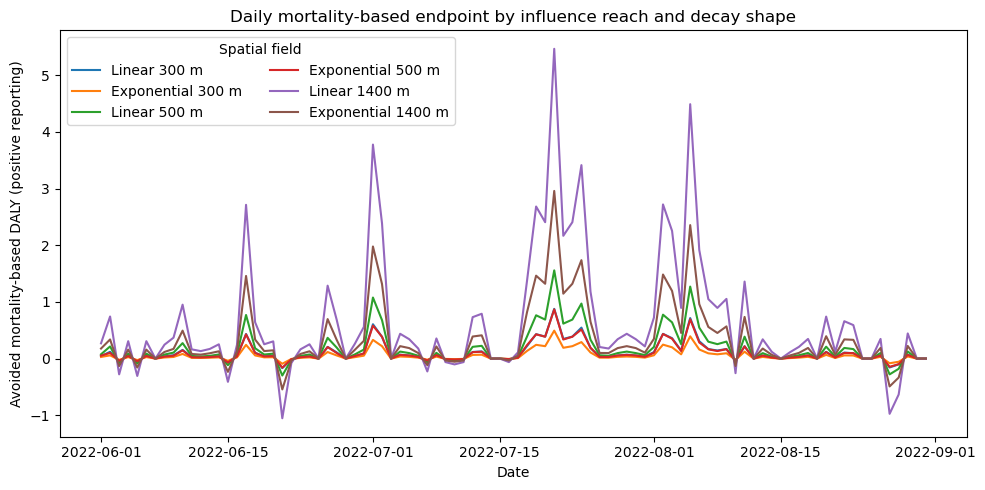

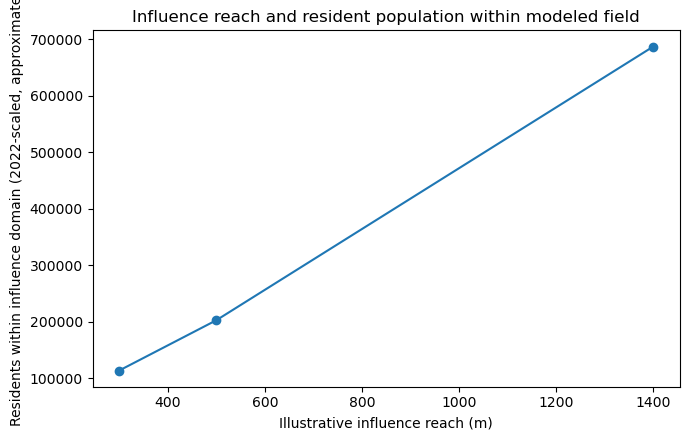

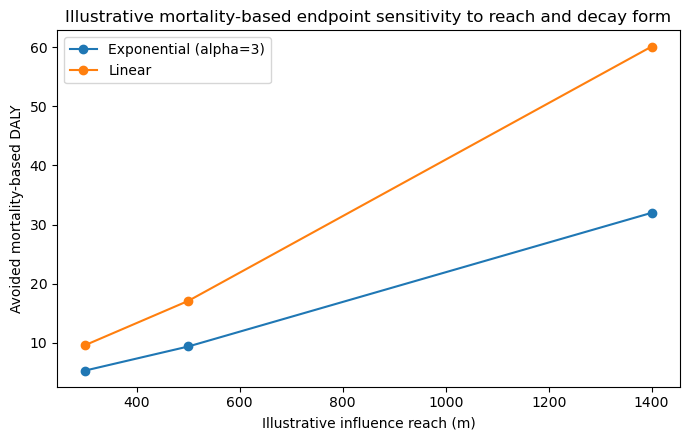

Nonlinear functional-form sensitivity:
 reach_m  exponential    linear  exponential_vs_linear_pct
   300.0     5.332333  9.637712                 -44.672206
   500.0     9.397380 17.111390                 -45.081143
  1400.0    31.998972 60.112524                 -46.768211


In [17]:
# Daily endpoint contribution and spatial functional-form sensitivity figures

fig, ax = plt.subplots(figsize=(10, 5))
for cfg in SPATIAL_FIELD_SCENARIOS:
    x = scenario_tables[cfg["scenario"]]
    by_day = x.groupby("date", as_index=False)["EP_it_from_MPxF"].sum()
    ax.plot(by_day["date"], -by_day["EP_it_from_MPxF"], label=cfg["scenario"])

ax.set_xlabel("Date")
ax.set_ylabel("Avoided mortality-based DALY (positive reporting)")
ax.set_title("Daily mortality-based endpoint by influence reach and decay shape")
ax.legend(title="Spatial field", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_avoided_daly_by_reach_and_decay.png", dpi=200)
plt.show()

# Influence population is determined by the operational reach D and is therefore
# identical for linear and exponential shapes at the same D.
pop_by_reach = (
    summary.groupby("reach_m", as_index=False)[
        "population_within_influence_domain_2022_approx"
    ].first()
)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    pop_by_reach["reach_m"],
    pop_by_reach["population_within_influence_domain_2022_approx"],
    marker="o",
)
ax.set_xlabel("Illustrative influence reach (m)")
ax.set_ylabel("Residents within influence domain (2022-scaled, approximate)")
ax.set_title("Influence reach and resident population within modeled field")
fig.tight_layout()
fig.savefig(FIG_DIR / "reach_vs_affected_population.png", dpi=200)
plt.show()

# Mortality-based endpoint: compare decay shapes at the same literature-informed reach.
fig, ax = plt.subplots(figsize=(7, 4.5))
for decay_model, group in summary.groupby("decay_model"):
    group = group.sort_values("reach_m")
    label = "Linear" if decay_model == "linear" else f"Exponential (alpha={EXPONENTIAL_SHAPE_ALPHA:g})"
    ax.plot(
        group["reach_m"],
        group["EP_avoided_DALY_positive_reporting"],
        marker="o",
        label=label,
    )
ax.set_xlabel("Illustrative influence reach (m)")
ax.set_ylabel("Avoided mortality-based DALY")
ax.set_title("Illustrative mortality-based endpoint sensitivity to reach and decay form")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "reach_and_decay_vs_avoided_daly.png", dpi=200)
plt.show()

# Percent difference caused by nonlinear functional form at each common reach.
endpoint_pivot = summary.pivot(
    index="reach_m",
    columns="decay_model",
    values="EP_avoided_DALY_positive_reporting",
).reset_index()
if {"linear", "exponential"}.issubset(endpoint_pivot.columns):
    endpoint_pivot["exponential_vs_linear_pct"] = (
        (endpoint_pivot["exponential"] - endpoint_pivot["linear"])
        / endpoint_pivot["linear"]
        * 100.0
    )
    print("Nonlinear functional-form sensitivity:")
    print(endpoint_pivot.to_string(index=False))
    endpoint_pivot.to_csv(
        OUTPUT_DIR / "linear_vs_exponential_endpoint_sensitivity.csv",
        index=False,
    )

In [18]:
# Export spatial attributes and cell-day calculation tables

grid.to_file(
    OUTPUT_DIR / "central_park_receptor_grid.gpkg",
    layer="receptor_grid",
    driver="GPKG",
)

grid[
    ["cell_id", "a_i_m2", "P_i_2020", "P_i_2022"] + weight_cols + fraction_cols
].to_csv(
    OUTPUT_DIR / "receptor_grid_scenario_weights.csv",
    index=False,
)

for scenario_name, table in scenario_tables.items():
    safe_name = (
        scenario_name.replace(" ", "_")
        .replace("/", "_")
        .replace(".", "p")
    )
    cols = [
        "cell_id", "date", "P_i_2022", "spatial_weight", "influence_fraction",
        "T_epi_C", "deltaT_CP_C", "deltaT_GI_C", "T0_h_C", "TGI_h_C",
        "RR0", "RRGI", "CFm_it", "MP_it", "F_m_to_e_it",
        "CFe_it", "EP_it_from_MPxF", "EP_it_direct",
    ]
    table[cols].to_csv(
        OUTPUT_DIR / f"cell_day_{safe_name}.csv",
        index=False,
    )

print("Outputs written to:", OUTPUT_DIR.resolve())

Outputs written to: /Users/alanasmith/Documents/Jupyter_Notebooks/UHI LCR Method/NYC Case Study/lcr_outputs_continuous_rr


## Interpretation and reporting notes

1. **The temperature-influence fields are sensitivity scenarios.** The two station series do not identify the actual two-dimensional causal temperature footprint of Central Park.
2. **Linear and nonlinear fields use the same operational reaches.** The normalized exponential uses $\alpha=3$ as a functional-form sensitivity parameter; it is not fitted to Central Park and is not a universal decay coefficient.
3. **The station contrast retains its observed sign.** The calculation allows both cooling and warming days.
4. **The continuous $RR(T)$ relationship is evaluated for every study day.** No additional temperature reporting threshold is imposed in the LCIA calculation. The June-August physical midpoint and mortality-based endpoint therefore use the same daily study period.
5. **RR is evaluated at the receptor-cell/day resolution before aggregation.** The cell-average intervention temperature change is obtained by numerical spatial integration within each 100 m receptor cell.
6. **Resident population is a proxy for exposure.** Census residence does not fully represent daytime mobility, park visitors, workers, tourists, or unhoused populations.
7. **Areal allocation within Census blocks is an approximation.** Population is assumed to be uniformly distributed within each Census block for the polygon-overlap allocation. Building-level, dasymetric, or time-varying occupancy data can replace this step.
8. **The 2022 population basis preserves the 2020 fine-scale spatial pattern.** Each 2020 block count is multiplied by the citywide NYC population ratio $8{,}335{,}897/8{,}804{,}190$. This assumes that the relative spatial distribution within the study area did not change materially between 2020 and 2022.
9. **The four LCIA identities are checked numerically.** A scalar scenario-level $F_{m\rightarrow e}^{agg}$ is reported for software implementation; interpretation should be cautious if positive and negative midpoint contributions materially cancel.
10. **Characterization factors are site-specific.** A factor generated for one GI size, geometry, climate period, and temperature field should not be applied unchanged to a materially different GI design.
11. **Distance-decay nonlinearity and GI size-response nonlinearity are distinct.** The linear/exponential sensitivity examines how temperature response changes with distance from the park. It does not establish how changing park area, shape, canopy, or design changes the cooling amplitude or reach.

### Spatial-cooling references used to parameterize the demonstration

* Chang, C.-R., & Li, M.-H. (2014). *Effects of urban parks on the local urban thermal environment*. Urban Forestry & Urban Greening, 13, 672-681.
* Toparlar, Y., et al. (2018). *The effect of an urban park on the microclimate in its vicinity: a case study for Antwerp, Belgium*. International Journal of Climatology, 38(S1), e303-e322.
* Yan, H., Wu, F., & Dong, L. (2018). *Influence of a large urban park on the local urban thermal environment*. Science of the Total Environment, 622-623, 882-891.
* Ziter, C. D., Pedersen, E. J., Kucharik, C. J., & Turner, M. G. (2019). *Scale-dependent interactions between tree canopy cover and impervious surfaces reduce daytime urban heat during summer*. PNAS, 116, 7575-7580.
* Chaplin-Kramer, R., et al. (2017). *Life cycle assessment needs predictive spatial modelling for biodiversity and ecosystem services*. Nature Communications, 8, 15065.